# Estimating parameters in GNF viscosity models with `lmfit`
### Herschel–Bulkley and Carreau–Yasuda, with honest confidence intervals

This tutorial fits two generalized-Newtonian-fluid (GNF) models to steady-shear data:

| Model | Data fitted | Equation |
|---|---|---|
| **Herschel–Bulkley (HB)** | shear stress $\tau$ vs shear rate $\dot\gamma$ | $\tau = \tau_y + K\dot\gamma^{\,n}$ |
| **Carreau–Yasuda (CY)** | viscosity $\eta$ vs shear rate $\dot\gamma$ | $\eta = \eta_\infty + (\eta_0-\eta_\infty)\left[1+(\lambda\dot\gamma)^a\right]^{(n-1)/a}$ |

The point is not just to get numbers out. It is to learn **how much you can trust each number**, and what to do when the data can't support a parameter. The four themes:

1. **Confidence intervals for every parameter.** That means the quick covariance-based standard errors *and* profile-likelihood intervals. When they disagree, the profile interval is the more trustworthy one.
2. **Correlation and identifiability.** Some parameters trade off against each other (e.g. CY's $a$ against $\eta_0$ and $\lambda$). A flat valley in the objective function makes the optimizer wander and makes the error bars big.
3. **Fixing a parameter to get a decent fit for the others.** Fixing $a=2$ (or $\eta_\infty=0$) and then, if the data allow, releasing it. We also cover what fixing does to your confidence intervals: they become *conditional* on the fixed value.
4. **How much data a parameter needs.** $\tau_y$ needs low-shear-rate data where the yield stress dominates. $\eta_\infty$ needs data far out in the second Newtonian region, usually beyond what a rotational rheometer can reach. $a$ needs well-sampled data on *both* sides of the transition.

**Data.** All data here are **synthetic**, generated from known "true" parameters with 4 % multiplicative (log-normal) noise, which is typical of a good rotational rheometer. Synthetic data make the tutorial *checkable*: you can see whether each confidence interval actually contains the truth. To use your own data, replace the arrays `gd_*`, `tau_*`, and `eta_*`.

**Requirements:** `numpy`, `scipy`, `matplotlib`, `lmfit` (≥ 1.0). The optional MCMC cell at the end also needs `emcee`.

**Contents**
0. Setup and a 5-minute statistics primer
1. Herschel–Bulkley: fit, CIs, correlations, weighting, re-parameterization, how much low-rate data you need, a coverage check, **shear-rate windows that see only some parameters (§1.8)**
2. Carreau–Yasuda: initial guesses, the $\eta_\infty$ problem, the $a$ problem, staged fitting, how much data each parameter needs, **shear-rate windows and reduced models (§2.9)**, optional MCMC (§2.10)
3. Checklist and notes on tools (is `lmfit` the right choice?)

## 0. Setup

In [4]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import lmfit
from lmfit import Model

print("lmfit version:", lmfit.__version__)

# Consistent, colour-blind-friendly colours used throughout
C_DATA, C_FIT, C_ALT, C_TRUE = "#2a78d6", "#eb6834", "#1baf7a", "0.35"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False,
})

lmfit version: 1.3.4


### 0.1 A 5-minute statistics primer

**Least squares.** `lmfit` minimises $\chi^2 = \sum_i r_i^2$, where $r_i$ is the (optionally weighted) residual of point $i$.

**Fit in log space.** Rheometer errors are roughly a constant *percentage* of the measured value, not a constant number of pascals. A 4 % error on 0.05 Pa·s and a 4 % error on 50 Pa·s should count the same. Fitting $\ln y$ instead of $y$ makes the residuals homoscedastic, so every decade of shear rate gets a fair vote. (Weighting linear residuals by $1/y$ does almost the same thing.) Section 1.4 shows what goes wrong when you don't do this.

**Two kinds of confidence interval.**

* *Covariance (standard-error) intervals.* `lmfit` reports `stderr` from the curvature of $\chi^2$ at the minimum, i.e. a local quadratic approximation. A 95 % interval is $\hat p \pm t_{0.975,\,\nu}\,\mathrm{SE}$, where $\nu = N - P$ is the number of degrees of freedom. These are cheap and fine when $\chi^2$ really is close to a parabola near the minimum.
* *Profile-likelihood intervals* (`result.conf_interval()`). Fix the parameter at a trial value, **re-optimise all the others**, and see how much $\chi^2$ rises. `lmfit` uses an F-test: a value is inside the $(1-\alpha)$ interval if
$$\frac{\chi^2(p)-\chi^2_{\min}}{\chi^2_{\min}/\nu} \le F_{1-\alpha}(1,\nu).$$
Profile intervals can be asymmetric and can be one-sided (e.g. "$\eta_\infty < 0.03$ Pa·s"). They are the honest answer when the problem is nonlinear or a parameter is poorly determined.

**Unknown noise level.** By default (`scale_covar=True`) `lmfit` estimates the noise from the residuals ($s^2 = \chi^2_{\min}/\nu$). That is the right choice here because we don't supply measurement uncertainties.

**Correlation.** If two parameters are correlated at $|\rho| \gtrsim 0.95$, the data mostly constrain a *combination* of them. Their individual error bars blow up, and the optimizer can slide along a valley.

In [5]:
# ---------- helper functions used throughout the notebook ----------

def fmt(x, nd=4):
    # compact number formatting that survives None/inf/nan
    if x is None or not np.isfinite(x):
        return {np.inf: "+inf", -np.inf: "-inf"}.get(x, "n/a")
    return f"{x:.{nd}g}"


def safe_conf_interval(result, level=0.95):
    # Profile-likelihood CIs from lmfit; returns None (with a message) if lmfit can't compute them.
    # lmfit needs stderr estimates to start the search, so this fails when the covariance matrix is singular.
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return result.conf_interval(sigmas=[level])   # values < 1 are read as probabilities
    except Exception as err:
        print(f"conf_interval() failed: {type(err).__name__}: {err}")
        return None


def summarize(result, truth=None, ci=None, level=0.95):
    # Table of best-fit values, standard errors, and both kinds of 95 % CI.
    tcrit = stats.t.ppf(0.5 + level / 2, result.nfree)
    head = f"{'param':>8} {'best':>10} {'stderr':>10} {'rel.err':>8}   {'95% CI (stderr*t)':<24}"
    if ci is not None:
        head += f" {'95% CI (profile)':<24}"
    if truth is not None:
        head += f" {'true':>8}"
    print(head)
    print("-" * len(head))
    for name, p in result.params.items():
        tag = "" if p.vary else ("(derived)" if p.expr else "(fixed)")
        se = p.stderr if (p.vary or p.expr) else None
        if se is not None and np.isfinite(se) and p.value != 0:
            r_pct = 100 * se / abs(p.value)
            rel = f"{r_pct:7.1f}%" if r_pct < 1e4 else "  >1e4%"
            ci_se = f"[{fmt(p.value - tcrit * se)}, {fmt(p.value + tcrit * se)}]"
        else:
            rel, ci_se = "n/a".rjust(8), "n/a" if p.vary else tag
        line = f"{name:>8} {fmt(p.value):>10} {fmt(se):>10} {rel:>8}   {ci_se:<24}"
        if ci is not None:
            ci_pr = f"[{fmt(ci[name][0][1])}, {fmt(ci[name][-1][1])}]" if name in ci else tag
            line += f" {ci_pr:<24}"
        if truth is not None:
            line += f" {fmt(truth.get(name, np.nan)):>8}"
        print(line)
    print(f"\nN = {result.ndata}, free params = {result.nvarys}, chi-square = {result.chisqr:.4g}, "
          f"reduced chi-square = {result.redchi:.3g} (residual s.d. = {np.sqrt(result.redchi):.3g})")


def correlation_matrix(result):
    # Print the parameter correlation matrix computed from result.covar.
    if result.covar is None:
        print("No covariance matrix (uncertainties could not be estimated).")
        return None
    names = result.var_names
    sd = np.sqrt(np.diag(result.covar))
    corr = result.covar / np.outer(sd, sd)
    print(" " * 9 + "".join(f"{n:>9}" for n in names))
    for i, n in enumerate(names):
        print(f"{n:>9}" + "".join(f"{corr[i, j]:9.3f}" for j in range(len(names))))
    return corr


def profile(result, name, values):
    # Profile chi-square: fix `name` at each value, re-optimise every other free parameter.
    # Returns chi2 array and a dict with the re-optimised values of the other parameters.
    chi2 = np.full(len(values), np.nan)
    others = {k: np.full(len(values), np.nan) for k, p in result.params.items() if p.vary and k != name}
    for i, v in enumerate(values):
        pars = result.params.copy()
        pars[name].set(value=v, vary=False)
        r = result.model.fit(result.data, pars, weights=result.weights, **result.userkws)
        chi2[i] = r.chisqr
        for k in others:
            others[k][i] = r.params[k].value
    return chi2, others


def profile_threshold(result, level=0.95, nfix=1):
    # chi-square level that bounds the profile CI (same F-test lmfit's conf_interval uses).
    return result.chisqr * (1 + nfix * stats.f.ppf(level, nfix, result.nfree) / result.nfree)

---
## 1. Herschel–Bulkley: shear stress vs shear rate

$$\tau = \tau_y + K\,\dot\gamma^{\,n}$$

| parameter | meaning | units |
|---|---|---|
| $\tau_y$ | yield stress | Pa |
| $K$ | consistency index | Pa·sⁿ |
| $n$ | flow-behaviour index ($n<1$ shear-thinning) | – |

We fit **stress**, not viscosity. Stress is what the instrument measures more directly, and for a yield-stress fluid the apparent viscosity $\tau/\dot\gamma$ diverges at low rates, which magnifies errors.

### 1.1 Synthetic data
True parameters: $\tau_y = 12$ Pa, $K = 3.5$ Pa·sⁿ, $n = 0.45$. Shear rates run from 0.01 to 1000 s⁻¹ at 5 points per decade, with 4 % log-normal noise.

26 points; yield and viscous stresses are equal at gd_c = 15.5 1/s


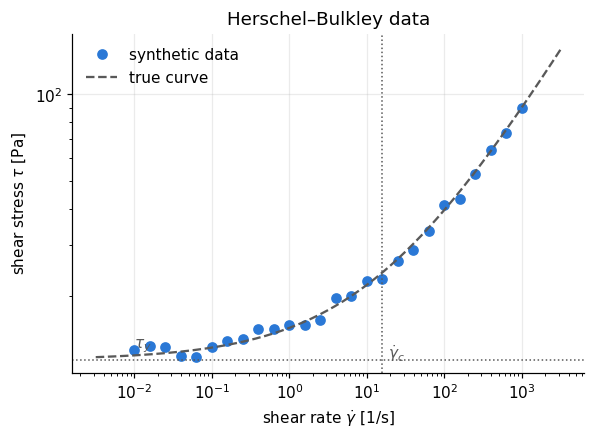

In [6]:
def hb(gd, tau_y, K, n):
    return tau_y + K * gd**n

def log_hb(gd, tau_y, K, n):
    # model for ln(tau): fitting in log space = fitting relative errors
    return np.log(tau_y + K * gd**n)

HB_TRUE = dict(tau_y=12.0, K=3.5, n=0.45)
NOISE = 0.04                      # 4 % relative noise (s.d. of ln tau)

def make_hb_data(gd_min, gd_max, pts_per_decade=5, noise=NOISE, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    npts = int(round(np.log10(gd_max / gd_min) * pts_per_decade)) + 1
    gd = np.logspace(np.log10(gd_min), np.log10(gd_max), npts)
    tau = hb(gd, **HB_TRUE) * np.exp(rng.normal(0.0, noise, gd.size))
    return gd, tau

rng = np.random.default_rng(2024)
gd_hb, tau_hb = make_hb_data(0.01, 1000, rng=rng)

# critical shear rate where the viscous term equals the yield stress
gd_c = (HB_TRUE["tau_y"] / HB_TRUE["K"]) ** (1 / HB_TRUE["n"])
print(f"{gd_hb.size} points; yield and viscous stresses are equal at gd_c = {gd_c:.1f} 1/s")

gfine = np.logspace(-2.5, 3.5, 300)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(gd_hb, tau_hb, "o", color=C_DATA, ms=6, label="synthetic data")
ax.loglog(gfine, hb(gfine, **HB_TRUE), "--", color=C_TRUE, lw=1.5, label="true curve")
ax.axhline(HB_TRUE["tau_y"], color=C_TRUE, lw=1, ls=":")
ax.axvline(gd_c, color=C_TRUE, lw=1, ls=":")
ax.text(gd_c * 1.2, 0.04, r"$\dot\gamma_c$", color=C_TRUE, transform=ax.get_xaxis_transform())
ax.text(1e-2, HB_TRUE["tau_y"] * 1.1, r"$\tau_y$", color=C_TRUE)
ax.set(xlabel=r"shear rate $\dot\gamma$ [1/s]", ylabel=r"shear stress $\tau$ [Pa]", title="Herschel–Bulkley data")
ax.legend(); plt.show()

### 1.2 Initial guesses and the fit

Good starting values matter little for a well-posed 3-parameter problem, but building the habit pays off for Carreau–Yasuda. A data-driven recipe:

* $\tau_y$: a bit below the stress at the lowest shear rate.
* $n$, $K$: slope and intercept of $\ln(\tau-\tau_y)$ vs $\ln\dot\gamma$ over the high-rate points.

Bounds: $\tau_y \ge 0$, $K > 0$, $0.05 \le n \le 1.5$. **Don't start a bounded parameter exactly on its bound.** `lmfit`'s default `leastsq` method enforces bounds with a variable transformation whose derivative is zero at the bound, so a parameter started there can get stuck.

In [7]:
def hb_guess(gd, tau):
    i = np.argsort(gd); gd, tau = gd[i], tau[i]
    tau_y0 = 0.8 * tau[0]
    hi = gd >= np.quantile(gd, 0.6)
    excess = np.clip(tau[hi] - tau_y0, 1e-12, None)
    n0, lnK0 = np.polyfit(np.log(gd[hi]), np.log(excess), 1)
    return dict(tau_y=tau_y0, K=np.exp(lnK0), n=float(np.clip(n0, 0.1, 1.0)))

hb_model = Model(log_hb)          # first argument (gd) is the independent variable
print("independent var:", hb_model.independent_vars, " params:", hb_model.param_names)

def hb_params(start):
    p = hb_model.make_params(**start)
    p["tau_y"].set(min=0.0)
    p["K"].set(min=1e-12)
    p["n"].set(min=0.05, max=1.5)
    return p

def fit_hb(gd, tau, start=None):
    start = hb_guess(gd, tau) if start is None else start
    return hb_model.fit(np.log(tau), hb_params(start), gd=gd)

guess = hb_guess(gd_hb, tau_hb)
print("initial guess:", {k: round(v, 3) for k, v in guess.items()})

res_hb = fit_hb(gd_hb, tau_hb)
print(res_hb.fit_report())

independent var: ['gd']  params: ['tau_y', 'K', 'n']
initial guess: {'tau_y': 10.371, 'K': 4.116, 'n': 0.424}
[[Model]]
    Model(log_hb)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 17
    # data points      = 26
    # variables        = 3
    chi-square         = 0.03434630
    reduced chi-square = 0.00149332
    Akaike info crit   = -166.363298
    Bayesian info crit = -162.589009
    R-squared          = 0.99624658
[[Variables]]
    tau_y:  12.3819345 +/- 0.22820486 (1.84%) (init = 10.37063)
    K:      3.24206785 +/- 0.23716261 (7.32%) (init = 4.115833)
    n:      0.45773935 +/- 0.01286352 (2.81%) (init = 0.4241878)
[[Correlations]] (unreported correlations are < 0.100)
    C(K, n)     = -0.9673
    C(tau_y, K) = -0.7916
    C(tau_y, n) = +0.7325


### 1.3 Confidence intervals: standard error vs profile

`fit_report()` gives standard errors and correlations. Below, `summarize()` puts the stderr-based 95 % CI next to the profile-likelihood CI from `conf_interval()`, along with the true values. For this well-designed experiment the two kinds of interval should agree closely, and each should contain the truth (on average 95 % of the time; see §1.7).

In [8]:
ci_hb = safe_conf_interval(res_hb)
summarize(res_hb, truth=HB_TRUE, ci=ci_hb)
print("\nCorrelation matrix:")
_ = correlation_matrix(res_hb)

   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
   tau_y      12.38     0.2282     1.8%   [11.91, 12.85]           [11.9, 12.85]                  12
       K      3.242     0.2372     7.3%   [2.751, 3.733]           [2.775, 3.763]                3.5
       n     0.4577    0.01286     2.8%   [0.4311, 0.4843]         [0.4315, 0.485]              0.45

N = 26, free params = 3, chi-square = 0.03435, reduced chi-square = 0.00149 (residual s.d. = 0.0386)

Correlation matrix:
             tau_y        K        n
    tau_y    1.000   -0.792    0.733
        K   -0.792    1.000   -0.967
        n    0.733   -0.967    1.000


Things to notice:

* **$n$ is the best-determined parameter** in relative terms, because it controls the slope across several decades.
* **$\tau_y$ and $K$ are negatively correlated.** If you over-estimate the yield stress, a smaller viscous term compensates.
* **$K$ and $n$ are strongly negatively correlated.** That is partly an artefact of the parameterization: $K$ is the viscous stress *at $\dot\gamma = 1$ s⁻¹*, which is just one point on the curve. Section 1.5 removes most of this correlation.

Next, the fit with a 95 % confidence band on the *mean curve*, from `eval_uncertainty`, and the residuals. Residuals should scatter randomly around zero with no trend. A systematic S-shape means the model is wrong, and then **no confidence interval means anything**.

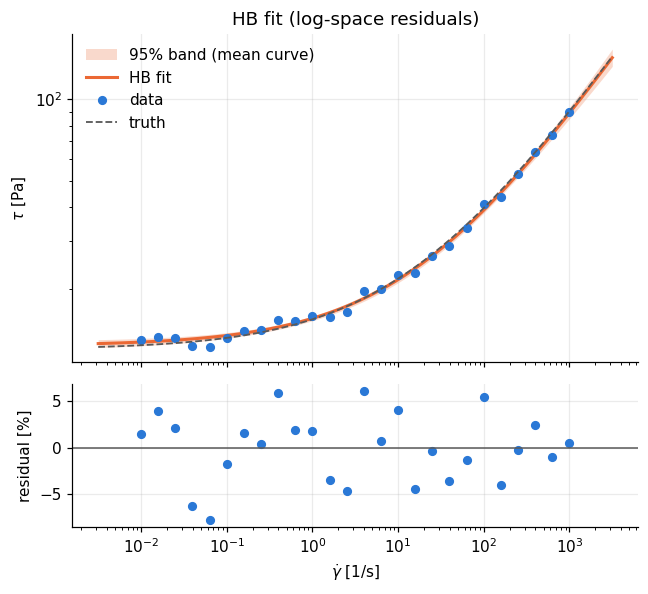

In [9]:
ln_fit = res_hb.eval(gd=gfine)
ln_band = res_hb.eval_uncertainty(gd=gfine, sigma=0.95)   # half-width of 95% band, in ln units

fig, (ax, axr) = plt.subplots(2, 1, figsize=(6, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
ax.fill_between(gfine, np.exp(ln_fit - ln_band), np.exp(ln_fit + ln_band), color=C_FIT, alpha=0.25, lw=0, label="95% band (mean curve)")
ax.loglog(gfine, np.exp(ln_fit), color=C_FIT, label="HB fit")
ax.loglog(gd_hb, tau_hb, "o", color=C_DATA, ms=5, label="data")
ax.loglog(gfine, hb(gfine, **HB_TRUE), "--", color=C_TRUE, lw=1.2, label="truth")
ax.set(ylabel=r"$\tau$ [Pa]", title="HB fit (log-space residuals)"); ax.legend()

axr.semilogx(gd_hb, 100 * res_hb.residual, "o", color=C_DATA, ms=5)
axr.axhline(0, color=C_TRUE, lw=1)
axr.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel="residual [%]")
plt.tight_layout(); plt.show()

### 1.4 Why weighting matters: unweighted fit in linear stress

A common mistake is to fit $\tau$ directly with unweighted least squares. The high-rate points have stresses of several hundred Pa, so their absolute residuals dominate $\chi^2$. The low-rate points, which are the ones that determine $\tau_y$, are effectively ignored. Compare the uncertainty in $\tau_y$:

UNWEIGHTED, linear stress residuals
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y      12.44     0.3254     2.6%   [11.77, 13.11]                 12
       K      3.184     0.2008     6.3%   [2.768, 3.599]                3.5
       n     0.4609   0.009437     2.0%   [0.4414, 0.4804]             0.45

N = 26, free params = 3, chi-square = 19.57, reduced chi-square = 0.851 (residual s.d. = 0.922)

LOG-SPACE residuals (from above)
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y      12.38     0.2282     1.8%   [11.91, 12.85]                 12
       K      3.242     0.2372     7.3%   [2.751, 3.733]                3.5
       n     0.4577    0.01286     2.8%   [0.4311, 0.4843]             0.45

N = 26, free params = 3, chi-square = 0.03435, reduced chi-square = 0.00

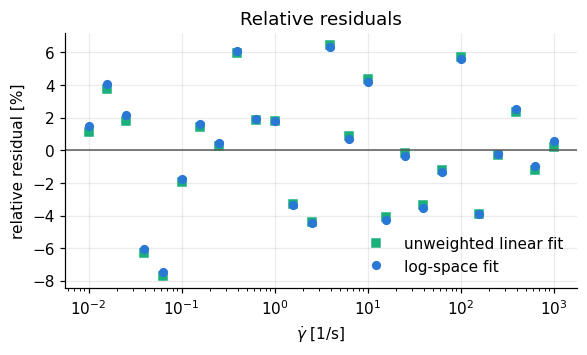

In [10]:
hb_lin_model = Model(hb)
p_lin = hb_lin_model.make_params(**guess)
p_lin["tau_y"].set(min=0); p_lin["K"].set(min=1e-12); p_lin["n"].set(min=0.05, max=1.5)
res_lin = hb_lin_model.fit(tau_hb, p_lin, gd=gd_hb)        # no weights, linear residuals

print("UNWEIGHTED, linear stress residuals")
summarize(res_lin, truth=HB_TRUE)
print("\nLOG-SPACE residuals (from above)")
summarize(res_hb, truth=HB_TRUE)

fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(gd_hb, 100 * (tau_hb / res_lin.best_fit - 1), "s", color=C_ALT, ms=5, label="unweighted linear fit")
ax.semilogx(gd_hb, 100 * (tau_hb / np.exp(res_hb.best_fit) - 1), "o", color=C_DATA, ms=5, label="log-space fit")
ax.axhline(0, color=C_TRUE, lw=1)
ax.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel="relative residual [%]", title="Relative residuals")
ax.legend(); plt.show()

The unweighted fit has a larger $\tau_y$ uncertainty, and its residual s.d. is in pascals rather than a relative error, so it doesn't describe the measurement noise. Its relative residuals are also uneven: tiny at high rates and larger at low rates, where the yield stress lives. The difference grows with noisier low-rate data or a wider stress range. If your rheometer software reports per-point uncertainties $\sigma_i$, the statistically correct alternative is `weights = 1/sigma_i` on linear residuals. Log residuals are the right default when you only know the errors are "about X %".

### 1.5 Re-parameterizing to reduce correlation

Write the viscous term relative to a reference shear rate $\dot\gamma_\text{ref}$ inside the data range:
$$\tau = \tau_y + K_\text{ref}\left(\dot\gamma/\dot\gamma_\text{ref}\right)^n, \qquad K = K_\text{ref}\,\dot\gamma_\text{ref}^{-n}.$$
This is the same model, but $K_\text{ref}$ (the viscous stress at $\dot\gamma_\text{ref}$) is pinned by nearby data instead of by an extrapolation to 1 s⁻¹. The fit becomes better conditioned, and the original $K$ comes back as a **derived parameter**: `lmfit`'s `expr=` propagates its uncertainty using the full covariance matrix.

A good $\dot\gamma_\text{ref}$ sits where the viscous term is well measured. The geometric mean of the rates above $\dot\gamma_c$ works well.

In [11]:
def log_hb_ref(gd, tau_y, K_ref, n, gd_ref=1.0):
    return np.log(tau_y + K_ref * (gd / gd_ref) ** n)

m_ref = Model(log_hb_ref)
gd_ref = float(np.exp(np.mean(np.log(gd_hb[gd_hb > gd_c]))))
print(f"gd_ref = {gd_ref:.3g} 1/s")

p_ref = m_ref.make_params(tau_y=guess["tau_y"], K_ref=guess["K"] * gd_ref ** guess["n"], n=guess["n"], gd_ref=gd_ref)
p_ref["gd_ref"].set(vary=False)                    # a constant, not a fit parameter
p_ref["tau_y"].set(min=0); p_ref["K_ref"].set(min=1e-12); p_ref["n"].set(min=0.05, max=1.5)
p_ref.add("K", expr="K_ref / gd_ref**n")           # derived parameter with propagated stderr

res_ref = m_ref.fit(np.log(tau_hb), p_ref, gd=gd_hb)
summarize(res_ref, truth=HB_TRUE)
print("\nCorrelation matrix (re-parameterized):")
_ = correlation_matrix(res_ref)

gd_ref = 126 1/s
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y      12.38     0.2282     1.8%   [11.91, 12.85]                 12
   K_ref      29.65     0.6058     2.0%   [28.4, 30.91]                 n/a
       n     0.4577    0.01286     2.8%   [0.4311, 0.4843]             0.45
  gd_ref      125.9        n/a      n/a   (fixed)                       n/a
       K      3.242     0.2372     7.3%   [2.751, 3.733]                3.5

N = 26, free params = 3, chi-square = 0.03435, reduced chi-square = 0.00149 (residual s.d. = 0.0386)

Correlation matrix (re-parameterized):
             tau_y    K_ref        n
    tau_y    1.000   -0.604    0.733
    K_ref   -0.604    1.000   -0.419
        n    0.733   -0.419    1.000


The fit is identical (same $\chi^2$, same $K$, same $\tau_y$, $n$). The difference is that the $K_\text{ref}$–$n$ correlation is much weaker than $K$–$n$ was. That matters for optimizer robustness on harder problems, and it shows that **much of the "uncertainty in $K$" is really uncertainty in $n$ projected back to 1 s⁻¹.** If you report $K$ and $n$ separately, also report their correlation, or report $K_\text{ref}$ at a rate inside your data.

### 1.6 How much low-shear-rate data do you need to pin down $\tau_y$?

$\tau_y$ is only "seen" where it is a significant fraction of the total stress, i.e. at $\dot\gamma \lesssim \dot\gamma_c = (\tau_y/K)^{1/n}$ (≈15 s⁻¹ here). Below we keep $\dot\gamma_\max = 1000$ s⁻¹, raise the lowest measured rate $\dot\gamma_\min$, and record the median relative standard error of each parameter over 30 noisy replicates.

  gd_min  gd_min/gd_c  tau_y/tau(gd_min)  rel.SE tau_y      rel.SE K      rel.SE n
   0.001     6.47e-05               0.99          1.4%          6.3%          2.5%
    0.01     0.000647               0.96          1.9%          7.0%          2.7%
     0.1      0.00647               0.91          3.3%          9.6%          3.6%
       1       0.0647               0.77          6.6%         14.9%          5.1%
       3        0.194               0.68          9.8%         18.6%          6.0%
      10        0.647               0.55         19.5%         30.7%          9.3%
      30         1.94               0.43         51.9%         50.7%         14.9%
     100         6.47               0.30         86.1%        115.0%         26.2%


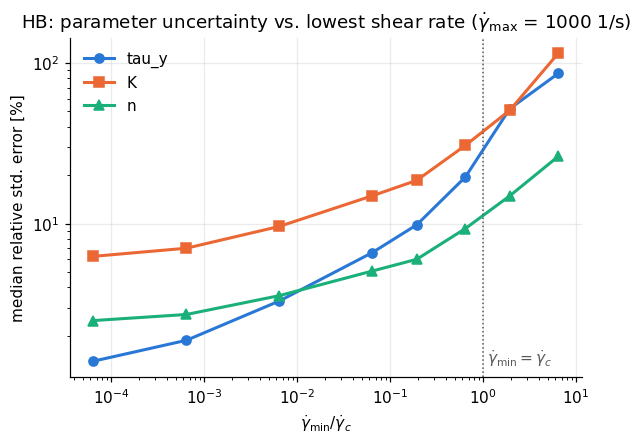

In [12]:
rng_d = np.random.default_rng(11)
gd_mins = np.array([1e-3, 1e-2, 1e-1, 1, 3, 10, 30, 100])
n_rep = 30
rel_se = {k: np.zeros(len(gd_mins)) for k in HB_TRUE}
for i, gmin in enumerate(gd_mins):
    tmp = {k: [] for k in HB_TRUE}
    for _ in range(n_rep):
        gd, tau = make_hb_data(gmin, 1000, rng=rng_d)
        r = fit_hb(gd, tau)
        for k in HB_TRUE:
            se = r.params[k].stderr
            tmp[k].append(se / r.params[k].value if (se is not None and r.params[k].value > 0) else np.inf)
    for k in HB_TRUE:
        rel_se[k][i] = np.median(tmp[k])

print(f"{'gd_min':>8} {'gd_min/gd_c':>12} {'tau_y/tau(gd_min)':>18}" + "".join(f"{'rel.SE '+k:>14}" for k in HB_TRUE))
for i, gmin in enumerate(gd_mins):
    frac = HB_TRUE["tau_y"] / hb(gmin, **HB_TRUE)
    print(f"{gmin:8.3g} {gmin/gd_c:12.3g} {frac:18.2f}" + "".join(f"{100*rel_se[k][i]:13.1f}%" for k in HB_TRUE))

fig, ax = plt.subplots(figsize=(6, 4))
for k, c, m in zip(HB_TRUE, [C_DATA, C_FIT, C_ALT], ["o", "s", "^"]):
    ax.loglog(gd_mins / gd_c, 100 * rel_se[k], marker=m, color=c, label=k)
ax.axvline(1, color=C_TRUE, lw=1, ls=":"); ax.text(1.1, 0.04, r"$\dot\gamma_\min=\dot\gamma_c$", color=C_TRUE, transform=ax.get_xaxis_transform())
ax.set(xlabel=r"$\dot\gamma_\min / \dot\gamma_c$", ylabel="median relative std. error [%]",
       title=r"HB: parameter uncertainty vs. lowest shear rate ($\dot\gamma_\max$ = 1000 1/s)")
ax.legend(); plt.show()

**Take-away.** The uncertainty in $\tau_y$ grows quickly once $\dot\gamma_\min$ passes $\dot\gamma_c$, i.e. once you have no data where the yield stress is at least comparable to the viscous stress. $K$ and $n$ suffer too, because they become entangled with $\tau_y$. Rule of thumb: **include at least one to two decades of shear rate below $\dot\gamma_c$**, where $\tau$ is visibly levelling off on a log–log plot.

Two practical caveats the statistics can't see. (1) At very low rates, wall slip, start-up transients, and thixotropy can bias the stress. Low-rate data must be steady and slip-free (roughened or vane geometries) to be useful. (2) A small $\tau_y$ uncertainty means the yield stress *of the HB model* is well determined. Whether the material has a "true" yield stress is a separate physical question.

### 1.7 Do the intervals mean what they claim? A coverage check

Synthetic data let us test the 95 % stderr-based intervals: generate many datasets, fit each, and count how often the interval contains the truth. A correct 95 % interval covers the truth in ~95 % of replicates. We compare the well-designed range (0.01–1000 s⁻¹) with a poor one (starting at 30 s⁻¹, above $\dot\gamma_c$).

In [13]:
def coverage(gd_min, n_rep=200, level=0.95, seed=5):
    rng_c = np.random.default_rng(seed)
    hits = {k: 0 for k in HB_TRUE}; n_ok = 0
    for _ in range(n_rep):
        gd, tau = make_hb_data(gd_min, 1000, rng=rng_c)
        r = fit_hb(gd, tau)
        if not r.errorbars:
            continue
        n_ok += 1
        t = stats.t.ppf(0.5 + level / 2, r.nfree)
        for k, v in HB_TRUE.items():
            hits[k] += abs(r.params[k].value - v) <= t * r.params[k].stderr
    return {k: h / n_ok for k, h in hits.items()}, n_ok

for gmin in [0.01, 30]:
    cov, n_ok = coverage(gmin)
    print(f"gd_min = {gmin:>5}: " + ", ".join(f"{k} {100*c:.0f}%" for k, c in cov.items()) + f"   ({n_ok} fits with error bars)")

gd_min =  0.01: tau_y 98%, K 96%, n 98%   (200 fits with error bars)
gd_min =    30: tau_y 92%, K 90%, n 93%   (199 fits with error bars)


With good data the coverage is close to the nominal 95 %. With poor data it can drop below nominal, because the quadratic approximation behind `stderr` breaks down when the $\chi^2$ surface is curved and banana-shaped. That is when to **prefer the profile intervals from `conf_interval()`**, or MCMC (§2.10).

### 1.8 Shear-rate windows: which parameters can a given range "see"?

So far we've varied the *edges* of the data range. Now take the opposite view: give the fit data from **only one region** of the flow curve and ask which parameters that region can determine. Each Herschel–Bulkley parameter "lives" in a different region:

| window | shear rates (here) | what the stress looks like | can determine |
|---|---|---|---|
| **yield-dominated** | 0.001–0.1 s⁻¹ ($\dot\gamma \ll \dot\gamma_c$) | almost flat, $\tau\approx\tau_y$ | $\tau_y$ only |
| **crossover** | 2–100 s⁻¹ (around $\dot\gamma_c\approx 15$ s⁻¹) | curving | all three, but correlated |
| **viscous-dominated** | 10⁴–10⁶ s⁻¹ ($\dot\gamma \gg \dot\gamma_c$; $\tau_y$ is < 5 % of $\tau$) | a straight power law | $K$, $n$ (and only an upper bound on $\tau_y$) |
| full | 0.001–10⁶ s⁻¹ | everything | all three, well |

(10⁶ s⁻¹ is beyond a rotational rheometer. The point here is the principle: the viscous-dominated window must sit far enough above $\dot\gamma_c$ that the yield stress is a few percent of the total stress or less.)

The tool that makes this quantitative is the **logarithmic sensitivity** of the model to each parameter:
$$S_p(\dot\gamma) = \frac{\partial \ln \tau}{\partial \ln p}\,,$$
i.e. the % change in predicted stress per % change in parameter $p$. Since we fit $\ln\tau$, a parameter can only be estimated from points where $|S_p|$ is large compared with the noise (4 %). It must also have a *shape* across the window that differs from the other parameters' sensitivities. If two sensitivity curves are proportional over the window, the data can only determine a combination of the two parameters.

For HB: $S_{\tau_y} = \tau_y/\tau$, $\;S_K = K\dot\gamma^n/\tau$, $\;S_n = n\ln(\dot\gamma)\,K\dot\gamma^n/\tau$.

*Aside — stress or viscosity?* The HB viscosity form is $\eta = \tau/\dot\gamma = \tau_y/\dot\gamma + K\dot\gamma^{\,n-1}$. With log residuals, fitting $\ln\eta$ is **exactly** the same problem as fitting $\ln\tau$, because $\ln\eta = \ln\tau - \ln\dot\gamma$ and the $\ln\dot\gamma$ term contains no parameters. Everything in this section applies to HB viscosity data unchanged. A quick check:

In [14]:
def log_hb_visc(gd, tau_y, K, n):
    return np.log(tau_y / gd + K * gd ** (n - 1))

eta_hb = tau_hb / gd_hb                                   # the same data, expressed as viscosity
m_visc = Model(log_hb_visc)
p_visc = m_visc.make_params(**hb_guess(gd_hb, tau_hb))
p_visc["tau_y"].set(min=0.0); p_visc["K"].set(min=1e-12); p_visc["n"].set(min=0.05, max=1.5)
res_visc = m_visc.fit(np.log(eta_hb), p_visc, gd=gd_hb)
for k in HB_TRUE:
    print(f"{k:>6}: stress fit {res_hb.params[k].value:.5g} ± {res_hb.params[k].stderr:.3g}   "
          f"viscosity fit {res_visc.params[k].value:.5g} ± {res_visc.params[k].stderr:.3g}")

 tau_y: stress fit 12.382 ± 0.228   viscosity fit 12.382 ± 0.228
     K: stress fit 3.2421 ± 0.237   viscosity fit 3.2421 ± 0.237
     n: stress fit 0.45774 ± 0.0129   viscosity fit 0.45774 ± 0.0129


#### 1.8.1 Sensitivity curves

Below are the three sensitivities over seven decades, with the three partial windows shaded. Read each window vertically: which curves are far from zero there, and do they have different shapes?

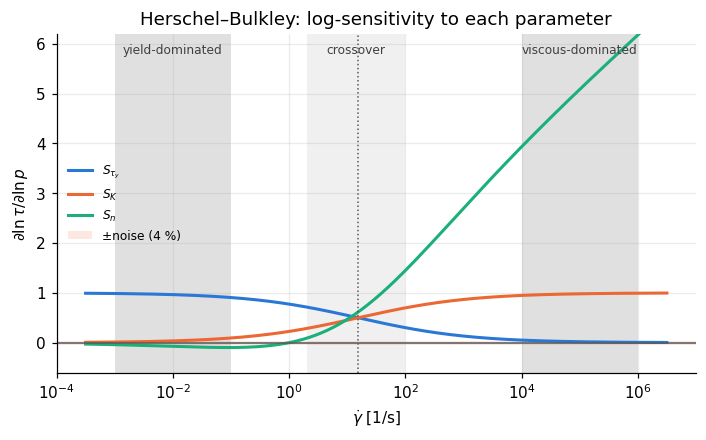

In [15]:
def log_sensitivity(fn, gd, pars, h=1e-4):
    # S_p = d ln(model) / d ln(p) for every parameter, by central differences in ln p.
    out = {}
    for k, v in pars.items():
        up = dict(pars, **{k: v * (1 + h)})
        dn = dict(pars, **{k: v * (1 - h)})
        out[k] = (np.log(fn(gd, **up)) - np.log(fn(gd, **dn))) / (np.log1p(h) - np.log1p(-h))
    return out

def shade_windows(ax, windows, ymax_frac=0.97):
    # Shade each partial window (skip the one labelled 'full') and label it at the top.
    for j, (label, lo, hi) in enumerate(w for w in windows if w[0] != "full"):
        ax.axvspan(lo, hi, color="0.88" if j % 2 == 0 else "0.94", zorder=0, lw=0)
        ax.text(np.sqrt(lo * hi), ymax_frac, label, transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color="0.25")

HB_WINDOWS = [("yield-dominated", 1e-3, 1e-1), ("crossover", 2.0, 100.0),
              ("viscous-dominated", 1e4, 1e6), ("full", 1e-3, 1e6)]
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order

g_s = np.logspace(-3.5, 6.5, 400)
S_hb = log_sensitivity(hb, g_s, HB_TRUE)
fig, ax = plt.subplots(figsize=(7.5, 4))
shade_windows(ax, HB_WINDOWS)
HB_LABELS = {"tau_y": r"$S_{\tau_y}$", "K": r"$S_K$", "n": r"$S_n$"}
for (k, s), c in zip(S_hb.items(), SERIES_COLORS):
    ax.semilogx(g_s, s, color=c, label=HB_LABELS[k])
ax.axhline(0, color=C_TRUE, lw=1)
ax.axhspan(-NOISE, NOISE, color=C_FIT, alpha=0.15, lw=0, label="±noise (4 %)")
ax.axvline(gd_c, color=C_TRUE, ls=":", lw=1)
ax.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel=r"$\partial\ln\tau/\partial\ln p$",
       title="Herschel–Bulkley: log-sensitivity to each parameter", ylim=(-0.6, 6.2))
ax.legend(loc="center left", fontsize=8); plt.show()

* In the **yield-dominated** window $S_{\tau_y}\approx 1$, while $S_K$ and $S_n$ are close to zero: a 10 % change in $K$ changes the stress by much less than the noise.
* In the **viscous-dominated** window it's the reverse: $S_{\tau_y}$ shrinks toward zero, and $S_K\approx1$ and $S_n$ carry the information.
* $S_n$ changes sign at $\dot\gamma = 1$ s⁻¹. That is just because $K$ is defined at 1 s⁻¹ (§1.5), and it is why $K$ and $n$ are so correlated when the data sit far from 1 s⁻¹.

#### 1.8.2 Expected uncertainty in each window (no fitting needed)

To first order, the covariance of the log-parameters is $\sigma^2 (S^\top S)^{-1}$, where $S$ is the $N\times P$ matrix of sensitivities at the measured shear rates and $\sigma$ is the noise in $\ln\tau$. This gives the **expected relative standard error** of each parameter for a given experimental design, *before you measure anything*. We compute two versions:

* **conditional**: $\sigma/\sqrt{\sum_i S_{p,i}^2}$, the error if all *other* parameters were known exactly. This measures whether the window "sees" the parameter at all.
* **marginal**: $\sigma\sqrt{[(S^\top S)^{-1}]_{pp}}$, the error when all parameters are fitted together. This is what a fit will actually report. (The code computes it equivalently as $\sigma$ divided by the part of $S_p$ that the other parameters' sensitivities *cannot* reproduce. That stays meaningful even when some other parameters are completely invisible.)

The ratio marginal/conditional is the price paid for correlation with the other parameters. Each window here has 10 points per decade.

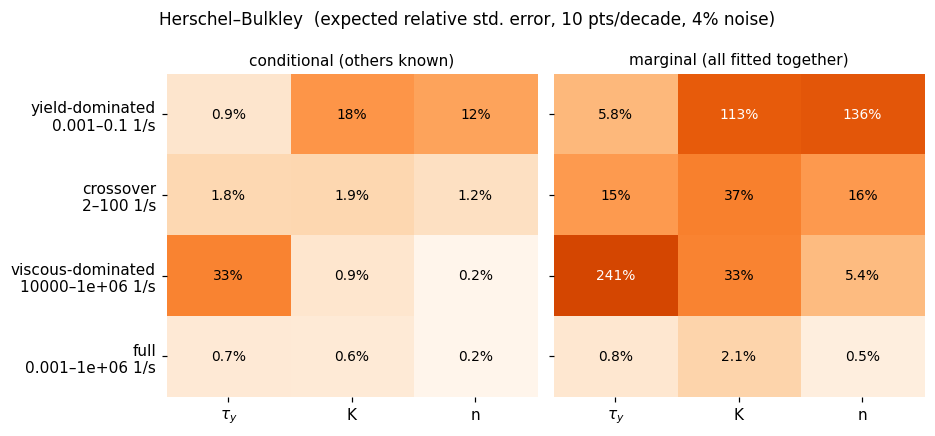

In [16]:
def expected_rel_se(fn, truth, gd, noise=NOISE):
    # First-order expected relative standard errors (conditional, marginal) from the sensitivity matrix S.
    names = list(truth)
    S_all = log_sensitivity(fn, gd, truth)
    S = np.column_stack([S_all[k] for k in names])
    cond = noise / np.sqrt((S ** 2).sum(axis=0))
    # marginal: the part of S_p that the other parameters cannot mimic. sigma/||residual|| equals
    # sigma*sqrt([(S^T S)^-1]_pp) when S^T S is invertible, and stays meaningful when some OTHER
    # parameters are collinear with each other (e.g. eta0 on the plateau while lam, a, n are invisible).
    marg = np.empty(len(names))
    for j in range(len(names)):
        others = np.delete(S, j, axis=1)
        coef, *_ = np.linalg.lstsq(others, S[:, j], rcond=1e-10)
        resid = np.linalg.norm(S[:, j] - others @ coef)
        marg[j] = noise / resid if resid > 1e-8 * np.linalg.norm(S[:, j]) else np.inf
    return cond, marg

def window_grid(lo, hi, ppd=10):
    return np.logspace(np.log10(lo), np.log10(hi), int(round(np.log10(hi / lo) * ppd)) + 1)

def se_heatmaps(fn, truth, windows, title, ppd=10, labels=None):
    names = list(truth)
    labels = labels or names
    cond = np.zeros((len(windows), len(names))); marg = np.zeros_like(cond)
    for i, (_, lo, hi) in enumerate(windows):
        cond[i], marg[i] = expected_rel_se(fn, truth, window_grid(lo, hi, ppd))
    fig, axs = plt.subplots(1, 2, figsize=(2.0 + 2.2 * len(names), 0.55 * len(windows) + 1.8), sharey=True)
    for ax, M, sub in zip(axs, [cond, marg], ["conditional (others known)", "marginal (all fitted together)"]):
        pct = 100 * M
        shade = np.log10(np.clip(pct, 0.3, 1000))
        ax.imshow(shade, cmap="Oranges", vmin=np.log10(0.3), vmax=3.3, aspect="auto")
        for i in range(len(windows)):
            for j in range(len(names)):
                v = pct[i, j]
                txt = "∞" if not np.isfinite(v) else (">1000%" if v > 1000 else (f"{v:.1f}%" if v < 10 else f"{v:.0f}%"))
                ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                        color="white" if shade[i, j] > 2.0 else "black")
        ax.set_xticks(range(len(names)), labels)
        ax.set_yticks(range(len(windows)), [f"{w[0]}\n{w[1]:g}–{w[2]:g} 1/s" for w in windows])
        ax.grid(False); ax.set_title(sub, fontsize=10)
        for spine in ax.spines.values(): spine.set_visible(False)
    fig.suptitle(title + f"  (expected relative std. error, {ppd} pts/decade, {NOISE:.0%} noise)", fontsize=11)
    plt.tight_layout(); plt.show()
    return cond, marg

cond_hb, marg_hb = se_heatmaps(hb, HB_TRUE, HB_WINDOWS, "Herschel–Bulkley", labels=[r"$\tau_y$", "K", "n"])

How to read the two maps:

* **Yield-dominated window:** $\tau_y$ is determined to a few percent. $K$ and $n$ are poorly determined even *conditionally*: the data barely respond to them.
* **Viscous-dominated window:** $n$ is well determined. $\tau_y$ is not, because its effect is buried in the noise. $K$ is visible conditionally, but its marginal error is much larger. That is the $K$–$n$ correlation from defining $K$ at 1 s⁻¹, four decades below the data. Re-parameterizing with $K_\text{ref}$ (§1.5) at, say, 10⁵ s⁻¹ would remove most of it.
* **Crossover window:** every parameter is "seen" (moderate conditional errors), but the marginal errors are several times larger. Over a narrow window the three sensitivity curves have similar shapes, so they trade off.
* **Full range:** each parameter has its own region, so conditional ≈ marginal and everything is small.

These numbers are first-order (linearized) predictions. The next cell checks them against real `lmfit` fits.

#### 1.8.3 Real fits in each window

One synthetic dataset per window, fitted with all three parameters free. We **start at the true values** on purpose, so any failure here reflects missing information in the data, not a bad initial guess. The fitted curve and its 95 % band are drawn over the *whole* shear-rate range: inside the window the band is narrow; outside, it shows what the data couldn't pin down.

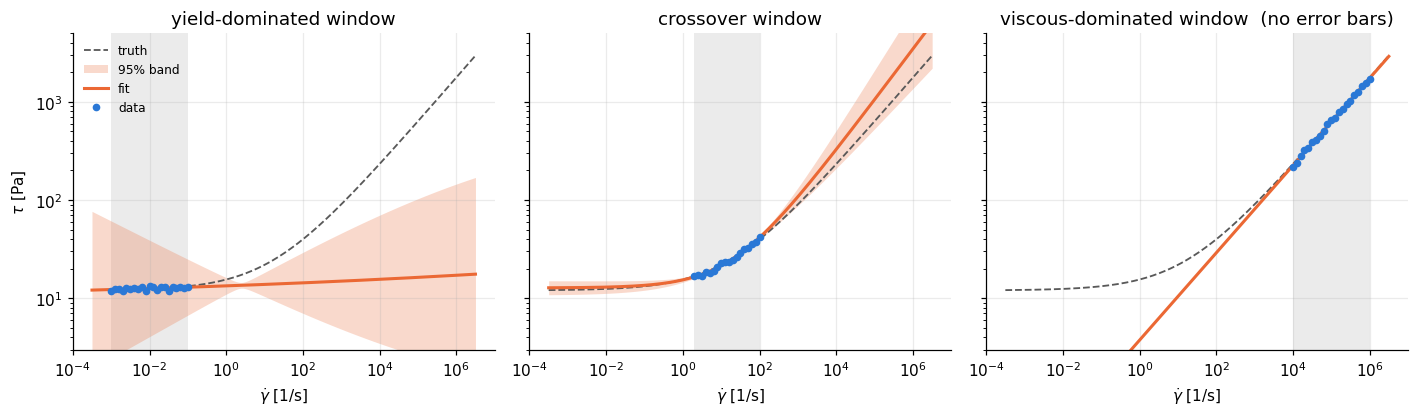


===== yield-dominated window (0.001–0.1 1/s, 21 points) =====
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y      9.566      42.71   446.4%   [-80.15, 99.29]                12
       K       3.79      41.53  1095.8%   [-83.47, 91.05]               3.5
       n       0.05     0.4303   860.7%   [-0.8541, 0.9541]            0.45

N = 21, free params = 3, chi-square = 0.02039, reduced chi-square = 0.00113 (residual s.d. = 0.0337)

===== crossover window (2–100 1/s, 18 points) =====
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y      12.74      1.003     7.9%   [10.6, 14.87]                  12
       K      2.639     0.6341    24.0%   [1.288, 3.991]                3.5
       n     0.5194    0.04891     9.4%   [0.4152, 0.6237]             0.45

N = 18, free params =

In [17]:
rng_w = np.random.default_rng(31)
win_fits_hb = {}
g_plot = np.logspace(-3.5, 6.5, 300)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (label, lo, hi) in zip(axs, HB_WINDOWS[:3]):
    gd_w, tau_w = make_hb_data(lo, hi, pts_per_decade=10, rng=rng_w)
    r = hb_model.fit(np.log(tau_w), hb_params(HB_TRUE), gd=gd_w)
    win_fits_hb[label] = (gd_w, tau_w, r)
    ax.axvspan(lo, hi, color="0.92", zorder=0, lw=0)
    ax.loglog(g_plot, hb(g_plot, **HB_TRUE), "--", color=C_TRUE, lw=1.2, label="truth")
    ln_fit = r.eval(gd=g_plot)
    if r.errorbars:
        band = np.clip(r.eval_uncertainty(gd=g_plot, sigma=0.95), 0, 5)
        ax.fill_between(g_plot, np.exp(ln_fit - band), np.exp(ln_fit + band), color=C_FIT, alpha=0.25, lw=0, label="95% band")
    ax.loglog(g_plot, np.exp(ln_fit), color=C_FIT, label="fit")
    ax.loglog(gd_w, tau_w, "o", color=C_DATA, ms=4, label="data")
    ax.set(title=f"{label} window" + ("" if r.errorbars else "  (no error bars)"), xlabel=r"$\dot\gamma$ [1/s]", ylim=(3, 5e3))
axs[0].set_ylabel(r"$\tau$ [Pa]"); axs[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

for label, (gd_w, tau_w, r) in win_fits_hb.items():
    print(f"\n===== {label} window ({gd_w.min():g}–{gd_w.max():g} 1/s, {gd_w.size} points) =====")
    summarize(r, truth=HB_TRUE)

The fits broadly agree with the predictions. In the yield-dominated window the band fans out at high rates: $K$ and $n$ are free to do almost anything there. Depending on the noise realisation, even $\tau_y$ can come out poorly in that window. If the optimizer drives $n$ toward its lower bound, $K\dot\gamma^{\,n}$ becomes almost constant and indistinguishable from $\tau_y$. That is a trade-off the linearized prediction (made at the true $n=0.45$) can't see. Fixing $n$, as in §1.8.4, removes it. In the viscous window $\tau_y$ typically runs to its bound of 0. `lmfit` then either can't estimate uncertainties at all (no band) or reports a band that opens wide at low rates, where $\tau_y$ would show up. Notice also that **every one of these fits looks perfect inside its window**, so a visually good fit says nothing about whether the parameters mean anything.

#### 1.8.4 What to report when you only have one window

**Viscous-dominated data only.** Don't report $\tau_y$ as a number. The profile gives an honest *upper bound*, and setting $\tau_y = 0$ (a plain power law) gives $K$ and $n$ with a small, quantifiable bias.

95% profile region for tau_y from viscous-only data: [0, 22] Pa   (true value 12.0 Pa)

Power law (tau_y fixed at 0) on the viscous-dominated window:
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
   tau_y          0        n/a      n/a   (fixed)                        12
       K       3.74     0.2119     5.7%   [3.296, 4.184]                3.5
       n     0.4446   0.004887     1.1%   [0.4344, 0.4548]             0.45

N = 21, free params = 2, chi-square = 0.01852, reduced chi-square = 0.000975 (residual s.d. = 0.0312)


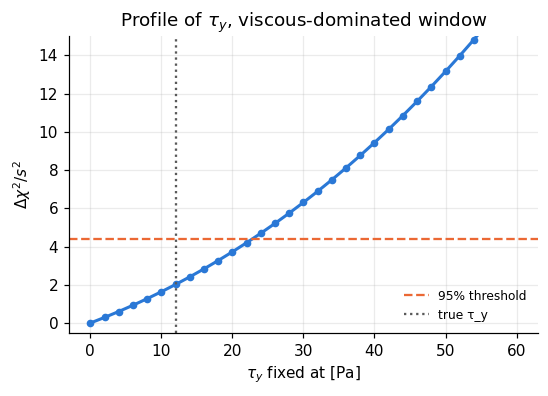

In [18]:
gd_v, tau_v, r_v = win_fits_hb["viscous-dominated"]
ty_grid = np.linspace(0, 60, 31)
chi2_ty, _ = profile(r_v, "tau_y", ty_grid)
thr_v = profile_threshold(r_v)
upper = ty_grid[chi2_ty <= thr_v].max()
print(f"95% profile region for tau_y from viscous-only data: [0, {upper:.0f}] Pa   (true value {HB_TRUE['tau_y']} Pa)")

p_pl = hb_params(HB_TRUE); p_pl["tau_y"].set(value=0.0, vary=False)      # power-law model
r_pl = hb_model.fit(np.log(tau_v), p_pl, gd=gd_v)
print("\nPower law (tau_y fixed at 0) on the viscous-dominated window:")
summarize(r_pl, truth=HB_TRUE)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(ty_grid, (chi2_ty - r_v.chisqr) / r_v.redchi, "o-", color=C_DATA, ms=4)
ax.axhline((thr_v - r_v.chisqr) / r_v.redchi, color=C_FIT, ls="--", lw=1.5, label="95% threshold")
ax.axvline(HB_TRUE["tau_y"], color=C_TRUE, ls=":", lw=1.5, label="true τ_y")
ax.set(xlabel=r"$\tau_y$ fixed at [Pa]", ylabel=r"$\Delta\chi^2/s^2$", title=r"Profile of $\tau_y$, viscous-dominated window",
       ylim=(-0.5, 15)); ax.legend(fontsize=8); plt.show()

**Yield-dominated data only.** Report $\tau_y$ alone. You can check that it doesn't depend on what you assume for the invisible parameters by refitting with $n$ fixed at very different values. $\tau_y$ barely moves, while $K$ swings by a large factor to compensate, which is a sign that $K$ is not being measured.

In [19]:
gd_y, tau_y_data, _ = win_fits_hb["yield-dominated"]
print(f"{'n fixed at':>10} {'tau_y':>14} {'K':>14} {'chi2':>9}")
for n_fix in [0.2, 0.45, 0.8, 1.0]:
    p = hb_params(HB_TRUE); p["n"].set(value=n_fix, vary=False)
    r = hb_model.fit(np.log(tau_y_data), p, gd=gd_y)
    print(f"{n_fix:10.2f} {r.params['tau_y'].value:8.3f} ± {fmt(r.params['tau_y'].stderr, 2):>4} "
          f"{r.params['K'].value:8.3g} ± {fmt(r.params['K'].stderr, 2):>5} {r.chisqr:9.5f}")

n fixed at          tau_y              K      chi2
      0.20   11.849 ± 0.34     1.78 ±   0.8   0.02078
      0.45   12.268 ± 0.18     2.08 ±     1   0.02146
      0.80   12.411 ± 0.13     3.95 ±   2.2   0.02226
      1.00   12.445 ± 0.12     6.04 ±   3.5   0.02262


**HB window take-aways**
* Each parameter needs data in the region where it dominates the stress: $\tau_y$ below $\dot\gamma_c$, and $K, n$ above it. **A window on one side of $\dot\gamma_c$ cannot give you the parameters that live on the other side**, however many points you take.
* A narrow window around $\dot\gamma_c$ sees everything but separates nothing well. Widen the range in both directions.
* Plot the sensitivities and compute the expected errors (§1.8.2) **before** you design the experiment. It takes seconds and tells you which shear rates you need.

---
## 2. Carreau–Yasuda: viscosity vs shear rate

$$\eta(\dot\gamma) = \eta_\infty + (\eta_0-\eta_\infty)\left[1+(\lambda\dot\gamma)^a\right]^{(n-1)/a}$$

| parameter | meaning | units | where in the data it is "seen" |
|---|---|---|---|
| $\eta_0$ | zero-shear viscosity | Pa·s | low-rate Newtonian plateau |
| $\eta_\infty$ | infinite-shear viscosity | Pa·s | second plateau at *very* high rates |
| $\lambda$ | time constant ($1/\lambda$ ≈ onset of shear thinning) | s | location of the transition |
| $a$ | Yasuda transition-sharpness parameter ($a=2$: Carreau) | – | *curvature* of the transition |
| $n$ | power-law index | – | slope of the shear-thinning region |

Five parameters with strongly overlapping effects. This is where identifiability problems show up.

### 2.1 Synthetic data
True parameters: $\eta_0=50$ Pa·s, $\eta_\infty=0.01$ Pa·s, $\lambda=2$ s, $a=1.5$, $n=0.35$, with 4 % noise. We create

* **Dataset A ("typical"):** 0.01–1000 s⁻¹, 5 points/decade. The zero-shear plateau is well covered; the second plateau is not reached.
* **Dataset B ("plateau barely reached"):** 0.3–1000 s⁻¹. The kind of data you get when low-rate torque is too small to measure. This is where $a$ misbehaves.

Dataset A: 26 pts, Dataset B: 19 pts
eta_inf / eta at 1000 1/s = 2.7%  (noise is 4% per point)
power-law branch reaches eta_inf at gd* ~ 2.5e+05 1/s


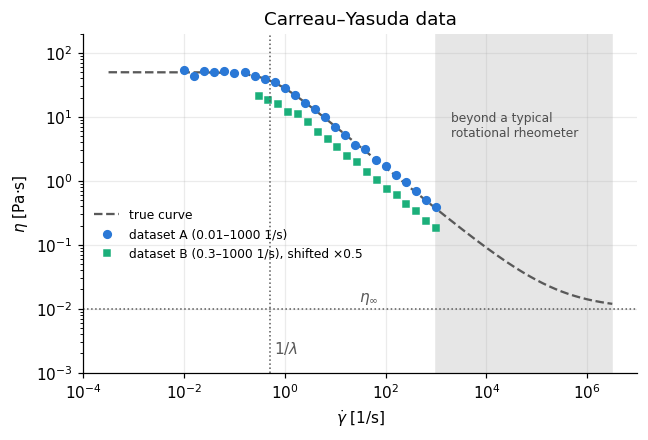

In [20]:
CY_NAMES = ["eta0", "eta_inf", "lam", "a", "n"]
CY_TRUE = dict(eta0=50.0, eta_inf=0.01, lam=2.0, a=1.5, n=0.35)

def cy(gd, eta0, eta_inf, lam, a, n):
    return eta_inf + (eta0 - eta_inf) * (1.0 + (lam * gd) ** a) ** ((n - 1.0) / a)

def log_cy(gd, eta0, eta_inf, lam, a, n):
    return np.log(cy(gd, eta0, eta_inf, lam, a, n))

def make_cy_data(gd_min, gd_max, pts_per_decade=5, noise=NOISE, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    npts = int(round(np.log10(gd_max / gd_min) * pts_per_decade)) + 1
    gd = np.logspace(np.log10(gd_min), np.log10(gd_max), npts)
    return gd, cy(gd, **CY_TRUE) * np.exp(rng.normal(0.0, noise, gd.size))

rng = np.random.default_rng(13)   # try other seeds: about 1 in 10 gives a spuriously "significant" eta_inf (e.g. 7)
gd_A, eta_A = make_cy_data(0.01, 1000, rng=rng)
gd_B, eta_B = make_cy_data(0.3, 1000, rng=np.random.default_rng(2))

# shear rate at which the power-law branch would fall to eta_inf
gd_star = (1 / CY_TRUE["lam"]) * (CY_TRUE["eta0"] / CY_TRUE["eta_inf"]) ** (1 / (1 - CY_TRUE["n"]))
print(f"Dataset A: {gd_A.size} pts, Dataset B: {gd_B.size} pts")
print(f"eta_inf / eta at 1000 1/s = {CY_TRUE['eta_inf']/cy(1000, **CY_TRUE):.1%}  (noise is {NOISE:.0%} per point)")
print(f"power-law branch reaches eta_inf at gd* ~ {gd_star:.2g} 1/s")

gf = np.logspace(-3.5, 6.5, 400)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(gf, cy(gf, **CY_TRUE), "--", color=C_TRUE, lw=1.5, label="true curve")
ax.loglog(gd_A, eta_A, "o", color=C_DATA, ms=5, label="dataset A (0.01–1000 1/s)")
ax.loglog(gd_B, eta_B * 0.5, "s", color=C_ALT, ms=4, label="dataset B (0.3–1000 1/s), shifted ×0.5")
ax.axhline(CY_TRUE["eta_inf"], color=C_TRUE, lw=1, ls=":"); ax.text(3e1, CY_TRUE["eta_inf"] * 1.3, r"$\eta_\infty$", color=C_TRUE)
ax.axvline(1 / CY_TRUE["lam"], color=C_TRUE, lw=1, ls=":"); ax.text(0.6, 2e-3, r"$1/\lambda$", color=C_TRUE)
ax.axvspan(1e3, gf[-1], color="0.9", zorder=0); ax.text(2e3, 5, "beyond a typical\nrotational rheometer", fontsize=8, color="0.3")
ax.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel=r"$\eta$ [Pa·s]", title="Carreau–Yasuda data", ylim=(1e-3, 200))
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.3), fontsize=8); plt.show()

Look at where $\eta_\infty$ actually matters: its contribution only exceeds the noise at shear rates several decades beyond the data. Keep that picture in mind.

### 2.2 Initial guesses from the data

A robust recipe:

* $\eta_0$: median of the three lowest-rate viscosities. (If the plateau isn't reached, this is a *lower bound*.)
* $n$: $1 +$ slope of $\ln\eta$ vs $\ln\dot\gamma$ over the highest-rate 20 % of points.
* $\lambda$: $1/\dot\gamma_{1/2}$, where $\dot\gamma_{1/2}$ is the rate at which $\eta$ has fallen to $\eta_0/2$.
* $a = 2$ (Carreau). This is the neutral, most common value.
* $\eta_\infty$: a small *positive* value (10 % of the lowest measured viscosity), **not** exactly 0, because of the bound issue mentioned in §1.2.

Bounds: $\eta_0,\lambda > 0$; $\eta_\infty \ge 0$; $0.1 \le a \le 10$; $0 \le n \le 1$.

In [21]:
cy_model = Model(log_cy)

def cy_guess(gd, eta):
    i = np.argsort(gd); gd, eta = gd[i], eta[i]
    eta0 = float(np.median(eta[:3]))
    k = max(3, len(gd) // 5)
    slope = np.polyfit(np.log(gd[-k:]), np.log(eta[-k:]), 1)[0]
    below = np.nonzero(eta < eta0 / 2)[0]
    gd_half = gd[below[0]] if below.size else gd[-1]
    return dict(eta0=eta0, eta_inf=0.1 * eta.min(), lam=1.0 / gd_half, a=2.0, n=float(np.clip(1 + slope, 0.05, 0.95)))

def cy_params(start, fix=None):
    # Parameters with bounds; `fix` = {name: value} holds those parameters constant.
    p = cy_model.make_params(**start)
    p["eta0"].set(min=1e-8)
    p["eta_inf"].set(min=0.0)
    p["lam"].set(min=1e-8)
    p["a"].set(min=0.1, max=10.0)
    p["n"].set(min=0.0, max=1.0)
    for k, v in (fix or {}).items():
        p[k].set(value=v, vary=False)
    return p

g0_A = cy_guess(gd_A, eta_A)
print("initial guess (A):", {k: float(f"{v:.3g}") for k, v in g0_A.items()})

initial guess (A): {'eta0': 51.7, 'eta_inf': 0.039, 'lam': 0.631, 'a': 2.0, 'n': 0.365}


### 2.3 Fit all five parameters to dataset A: meet the $\eta_\infty$ problem

In [22]:
res_A5 = cy_model.fit(np.log(eta_A), cy_params(g0_A), gd=gd_A)
ci_A5 = safe_conf_interval(res_A5)
summarize(res_A5, truth=CY_TRUE, ci=ci_A5)
print("\nCorrelation matrix:")
_ = correlation_matrix(res_A5)

   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
    eta0      50.44      1.091     2.2%   [48.17, 52.71]           [48.34, 52.82]                 50
 eta_inf    0.01009    0.03869   383.3%   [-0.07037, 0.09056]      [-inf, 0.08966]              0.01
     lam      2.166     0.1885     8.7%   [1.773, 2.558]           [1.789, 2.488]                  2
       a       1.66     0.2709    16.3%   [1.097, 2.224]           [1.246, 2.36]                 1.5
       n     0.3628    0.01664     4.6%   [0.3282, 0.3974]         [0.3251, 0.3806]             0.35

N = 26, free params = 5, chi-square = 0.04693, reduced chi-square = 0.00223 (residual s.d. = 0.0473)

Correlation matrix:
              eta0  eta_inf      lam        a        n
     eta0    1.000    0.173    0.100   -0.562   -0.243
  eta_inf    0.173    1.000   -0.718   -0.498   -0.898
     

The four "visible" parameters ($\eta_0, \lambda, a, n$) come out reasonably. $\eta_\infty$ is a different story. Typically its standard error is comparable to or larger than its value, its CI includes zero, or it ends up pinned at the lower bound of 0 (and then `lmfit` may report no stderr at all). **The data contain essentially no information about $\eta_\infty$.** Note also that the stderr-based interval can extend to *negative* viscosities, which is physically meaningless. That is a sign the symmetric quadratic approximation is the wrong tool here.

The profile makes this concrete. Fix $\eta_\infty$ on a log-spaced grid and re-optimise the other four parameters each time:

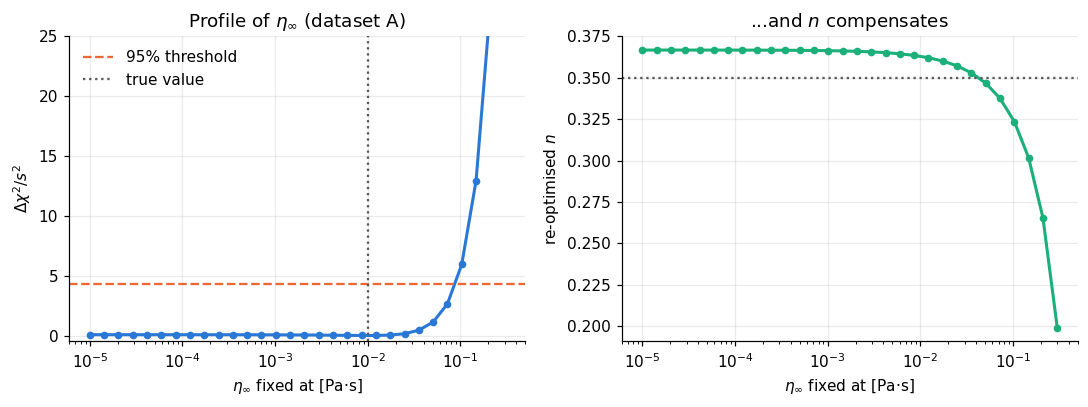

95% profile region for eta_inf: 1e-05 – 0.07237 Pa·s (grid spans 1e-05 – 0.3)


In [23]:
eta_inf_grid = np.logspace(-5, np.log10(0.3), 30)
chi2_ei, oth_ei = profile(res_A5, "eta_inf", eta_inf_grid)
thr = profile_threshold(res_A5)
chi2_min = min(res_A5.chisqr, np.nanmin(chi2_ei))
s2 = chi2_min / res_A5.nfree

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.semilogx(eta_inf_grid, (chi2_ei - chi2_min) / s2, "o-", color=C_DATA, ms=4)
ax1.axhline((thr - res_A5.chisqr) / s2, color=C_FIT, ls="--", lw=1.5, label="95% threshold")
ax1.axvline(CY_TRUE["eta_inf"], color=C_TRUE, ls=":", lw=1.5, label="true value")
ax1.set(xlabel=r"$\eta_\infty$ fixed at [Pa·s]", ylabel=r"$\Delta\chi^2 / s^2$", ylim=(-0.5, 25),
        title=r"Profile of $\eta_\infty$ (dataset A)"); ax1.legend()

ax2.semilogx(eta_inf_grid, oth_ei["n"], "o-", color=C_ALT, ms=4)
ax2.set(xlabel=r"$\eta_\infty$ fixed at [Pa·s]", ylabel=r"re-optimised $n$", title=r"...and $n$ compensates")
ax2.axhline(CY_TRUE["n"], color=C_TRUE, ls=":", lw=1.5)
plt.tight_layout(); plt.show()

inside = eta_inf_grid[chi2_ei <= thr]
print(f"95% profile region for eta_inf: {fmt(inside.min())} – {fmt(inside.max())} Pa·s (grid spans {eta_inf_grid[0]:.0e} – {eta_inf_grid[-1]:.1g})")

The profile is **flat** from $10^{-5}$ Pa·s up to some value, then rises. The data give only an **upper bound** on $\eta_\infty$, nothing more. Any value below that bound, including zero, is equally consistent with the measurements, and $n$ shifts slightly to compensate. A covariance-based "$\eta_\infty = x \pm y$" hides this; the profile shows it plainly.

### 2.4 Fix $\eta_\infty$ and compare models

When a parameter is unidentifiable you have three honest options:

1. **Fix it at zero** (a 4-parameter CY model). Usually the right choice for polymer melts.
2. **Fix it at a physically known value**, e.g. the solvent viscosity for a polymer solution or suspension, measured separately.
3. **Get data that constrain it** (§2.5).

Fixing is a one-liner in `lmfit`: `params['eta_inf'].set(value=0, vary=False)`. Then check whether the free parameter was "earning its keep", using the change in $\chi^2$ (F-test) and the information criteria AIC/BIC (lower is better; a difference below ~2 is not meaningful).

In [24]:
res_A4 = cy_model.fit(np.log(eta_A), cy_params(g0_A, fix=dict(eta_inf=0.0)), gd=gd_A)
ci_A4 = safe_conf_interval(res_A4)
summarize(res_A4, truth=CY_TRUE, ci=ci_A4)

# F-test for nested models: does freeing eta_inf reduce chi2 more than chance?
F = ((res_A4.chisqr - res_A5.chisqr) / 1) / (res_A5.chisqr / res_A5.nfree)
p_F = stats.f.sf(F, 1, res_A5.nfree)
print(f"\n                  chi2      AIC      BIC")
print(f"5-param (free)  {res_A5.chisqr:8.5f} {res_A5.aic:8.2f} {res_A5.bic:8.2f}")
print(f"4-param (fixed) {res_A4.chisqr:8.5f} {res_A4.aic:8.2f} {res_A4.bic:8.2f}")
print(f"F-test p-value for adding eta_inf: {p_F:.2f}  (large p => data do not support eta_inf)")

   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
    eta0       50.4      1.046     2.1%   [48.23, 52.57]           [48.37, 52.66]                 50
 eta_inf          0        n/a      n/a   (fixed)                  (fixed)                      0.01
     lam        2.2     0.1296     5.9%   [1.932, 2.469]           [1.945, 2.483]                  2
       a      1.693     0.2398    14.2%   [1.195, 2.19]            [1.32, 2.345]                 1.5
       n     0.3666   0.006999     1.9%   [0.3521, 0.3812]         [0.3517, 0.3804]             0.35

N = 26, free params = 4, chi-square = 0.04708, reduced chi-square = 0.00214 (residual s.d. = 0.0463)

                  chi2      AIC      BIC
5-param (free)   0.04693  -154.25  -147.96
4-param (fixed)  0.04708  -156.16  -151.13
F-test p-value for adding eta_inf: 0.80  (large p => data do no

For this dataset, fixing $\eta_\infty=0$ barely changes $\chi^2$, AIC and BIC favour the simpler model, and the remaining parameters' intervals get tighter (especially $n$, which no longer trades off against $\eta_\infty$). Note the small price: with the true $\eta_\infty=0.01$ set to 0, $n$ may be pulled slightly. That is a model-misspecification bias, and it is far smaller than the noise here.

> **Beware a lucky (unlucky) "detection".** Re-run §2.1 with `default_rng(7)`. With that noise realisation the 5-parameter fit returns $\eta_\infty \approx 0.06$ Pa·s, six times the truth, with an apparently respectable error bar and an F-test p ≈ 0.01. Correlated noise in the last few points, together with the strong $\eta_\infty$–$n$ correlation, mimics a second plateau. A parameter living at the edge of the data is the one most easily fooled by noise there. Ask whether the result is physically plausible, and whether it survives dropping the last one or two points.

### 2.5 How much data does $\eta_\infty$ need?

Extend $\dot\gamma_\max$ from $10^2$ to $10^6$ s⁻¹ (5 points/decade from 0.01 s⁻¹, 15 replicates each) and track the relative standard error of $\eta_\infty$ and how often the fit drives it to the bound of 0.

  gd_max  gd_max/gd*  eta_inf/eta(gd_max)  median rel.SE eta_inf  fits at bound
   1e+02     0.00041                 0.6%                   714%            47%
   1e+03      0.0041                 2.7%                   248%            40%
   1e+04       0.041                11.1%                    58%             0%
   3e+04        0.12                20.3%                    21%             0%
   1e+05        0.41                35.8%                    13%             0%
   3e+05         1.2                53.3%                     7%             0%
   1e+06         4.1                71.4%                     4%             0%


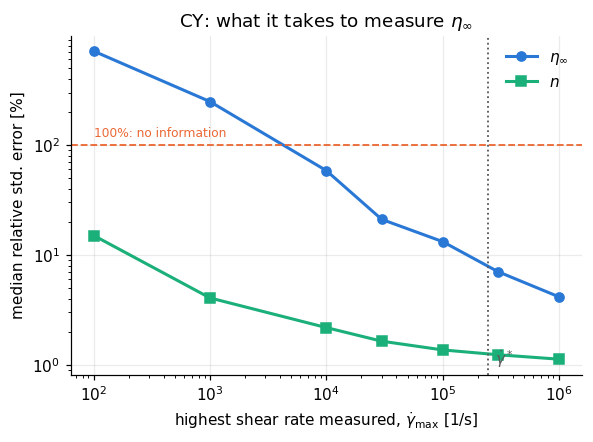

In [25]:
rng_e = np.random.default_rng(3)
gd_maxs = np.array([1e2, 1e3, 1e4, 3e4, 1e5, 3e5, 1e6])
n_rep = 15
med_rel, frac_bound, med_rel_n = [], [], []
for gmax in gd_maxs:
    rels, bnd, reln = [], 0, []
    for _ in range(n_rep):
        gd, eta = make_cy_data(0.01, gmax, rng=rng_e)
        r = cy_model.fit(np.log(eta), cy_params(cy_guess(gd, eta)), gd=gd)
        p = r.params["eta_inf"]
        if p.value < 1e-6:
            bnd += 1
        rels.append(p.stderr / p.value if (p.stderr is not None and p.value > 1e-6) else np.inf)
        reln.append(r.params["n"].stderr / r.params["n"].value if r.params["n"].stderr is not None else np.inf)
    med_rel.append(np.median(rels)); frac_bound.append(bnd / n_rep); med_rel_n.append(np.median(reln))

print(f"{'gd_max':>8} {'gd_max/gd*':>11} {'eta_inf/eta(gd_max)':>20} {'median rel.SE eta_inf':>22} {'fits at bound':>14}")
for gmax, mr, fb in zip(gd_maxs, med_rel, frac_bound):
    print(f"{gmax:8.0e} {gmax/gd_star:11.2g} {CY_TRUE['eta_inf']/cy(gmax, **CY_TRUE):20.1%} {100*mr:21.0f}% {fb:14.0%}")

fig, ax = plt.subplots(figsize=(6, 4))
mr = np.array(med_rel); ok = np.isfinite(mr)
ax.loglog(gd_maxs[ok], 100 * mr[ok], "o-", color=C_DATA, label=r"$\eta_\infty$")
ax.loglog(gd_maxs, 100 * np.array(med_rel_n), "s-", color=C_ALT, label=r"$n$")
ax.axhline(100, color=C_FIT, ls="--", lw=1.2); ax.text(gd_maxs[0], 120, "100%: no information", color=C_FIT, fontsize=8)
ax.axvline(gd_star, color=C_TRUE, ls=":", lw=1.2); ax.text(gd_star * 1.15, 1, r"$\dot\gamma^*$", color=C_TRUE)
ax.set(xlabel=r"highest shear rate measured, $\dot\gamma_\max$ [1/s]", ylabel="median relative std. error [%]",
       title=r"CY: what it takes to measure $\eta_\infty$"); ax.legend(); plt.show()

**Take-away.** $\eta_\infty$ becomes measurable only when the data reach within about a decade of the crossover rate
$$\dot\gamma^* \approx \frac{1}{\lambda}\left(\frac{\eta_0}{\eta_\infty}\right)^{1/(1-n)},$$
where the power-law branch has fallen to $\eta_\infty$. Equivalently, $\eta_\infty$ must contribute **well above the noise level** (here ≫ 4 %) to the viscosity at the highest rates. For a typical polymer system $\dot\gamma^*$ is $10^5$–$10^7$ s⁻¹, so you need capillary or slit rheometry, and those data come with their own corrections (Bagley, Rabinowitsch, viscous heating). Before reporting a fitted $\eta_\infty$ from rotational data, check its profile. A one-sided profile means "fix it".

### 2.6 The $a$ problem (dataset B)

On dataset B the zero-shear plateau is barely reached ($\lambda\dot\gamma_\min = 0.6$). Now $\eta_0$, $\lambda$ and $a$ can all trade off: a sharper transition (large $a$) with a lower plateau fits the visible data about as well as a gentler one (small $a$) with a higher plateau. Two symptoms:

1. **The answer depends on the starting point.** Some starts converge to a different, worse local minimum, often with $a$ near its upper bound and $\eta_0$, $\lambda$ inflated.
2. **Even the best fit has large, strongly correlated uncertainties in $a$ and $\eta_0$.**

#### 2.6.1 Symptom 1: multistart with all five parameters free

     chi2     eta0  eta_inf      lam        a        n  a_start
   0.0205     56.5   0.0403     2.05     1.08    0.326    0.866
   0.0205     56.5   0.0403     2.05     1.08    0.326     4.82
   0.0205     56.5   0.0403     2.05     1.08    0.326    0.447
   0.0205     56.5   0.0403     2.05     1.08    0.326     1.83
   0.0206       58   0.0439     2.09     1.03    0.323     6.09
   0.1952      723  7.2e-10      222     9.66     0.39     3.03
   0.3128 3.22e+03 1.46e-06 4.72e+03     8.13    0.421     1.93
   1.7820  1.2e+03 6.47e-06 4.68e+03     8.99    0.505     2.69
true            50     0.01        2      1.5     0.35


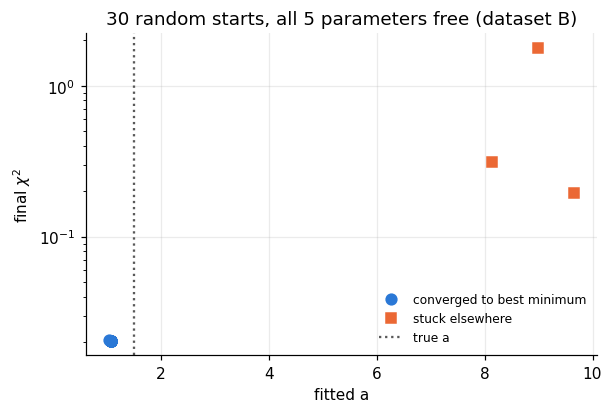

3 of 30 starts did not reach the best minimum.


In [26]:
rng_ms = np.random.default_rng(42)
rows = []
for i in range(30):
    start = dict(eta0=10 ** rng_ms.uniform(0.5, 3), eta_inf=10 ** rng_ms.uniform(-4, -1),
                 lam=10 ** rng_ms.uniform(-2, 2), a=10 ** rng_ms.uniform(-0.6, 0.95), n=rng_ms.uniform(0.1, 0.9))
    r = cy_model.fit(np.log(eta_B), cy_params(start), gd=gd_B)
    rows.append([r.chisqr] + [r.params[k].value for k in CY_NAMES] + [start["a"]])
rows = np.array(sorted(rows, key=lambda x: x[0]))

print(f"{'chi2':>9}" + "".join(f"{k:>9}" for k in CY_NAMES) + f"{'a_start':>9}")
for row in np.vstack([rows[:4], rows[-4:]]):   # 4 best and 4 worst starts
    print(f"{row[0]:9.4f}" + "".join(f"{v:9.3g}" for v in row[1:]))
print("true     " + "".join(f"{CY_TRUE[k]:9.3g}" for k in CY_NAMES))

best_chi2 = rows[0, 0]
fig, ax = plt.subplots(figsize=(6, 3.8))
good = rows[:, 0] < best_chi2 * 1.01
ax.semilogy(rows[good, 4], rows[good, 0], "o", color=C_DATA, ms=7, label="converged to best minimum")
ax.semilogy(rows[~good, 4], rows[~good, 0], "s", color=C_FIT, ms=7, label="stuck elsewhere")
ax.axvline(CY_TRUE["a"], color=C_TRUE, ls=":", lw=1.5, label="true a")
ax.set(xlabel="fitted a", ylabel=r"final $\chi^2$", title="30 random starts, all 5 parameters free (dataset B)"); ax.legend(fontsize=8)
plt.show()
print(f"{(~good).sum()} of {len(rows)} starts did not reach the best minimum.")

Depending on your `lmfit` version and optimizer some starts may all agree, but in practice you will often see fits that stopped with $a$ at an extreme and $\chi^2$ several times the best value. Even fits *near* the best $\chi^2$ can disagree noticeably in $a$ and $\eta_0$. That is the flat valley.

#### 2.6.2 Symptom 2: the profile of $a$ is shallow, and $\eta_0$ slides along it
From now on we fix $\eta_\infty = 0$ (lesson of §2.4), so the $a$ problem is isolated.

   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
    eta0      52.38      7.858    15.0%   [35.63, 69.13]           [42.38, 80.4]                  50
 eta_inf          0        n/a      n/a   (fixed)                  (fixed)                      0.01
     lam      2.072     0.4018    19.4%   [1.216, 2.928]           [1.538, 3.593]                  2
       a       1.29       0.33    25.6%   [0.5867, 1.993]          [0.785, 2.111]                1.5
       n     0.3481   0.008266     2.4%   [0.3305, 0.3657]         [0.3286, 0.3628]             0.35

N = 19, free params = 4, chi-square = 0.02239, reduced chi-square = 0.00149 (residual s.d. = 0.0386)

Correlation matrix:
              eta0      lam        a        n
     eta0    1.000    0.957   -0.943   -0.566
      lam    0.957    1.000   -0.830   -0.315
        a   -0.943   -0.830    1

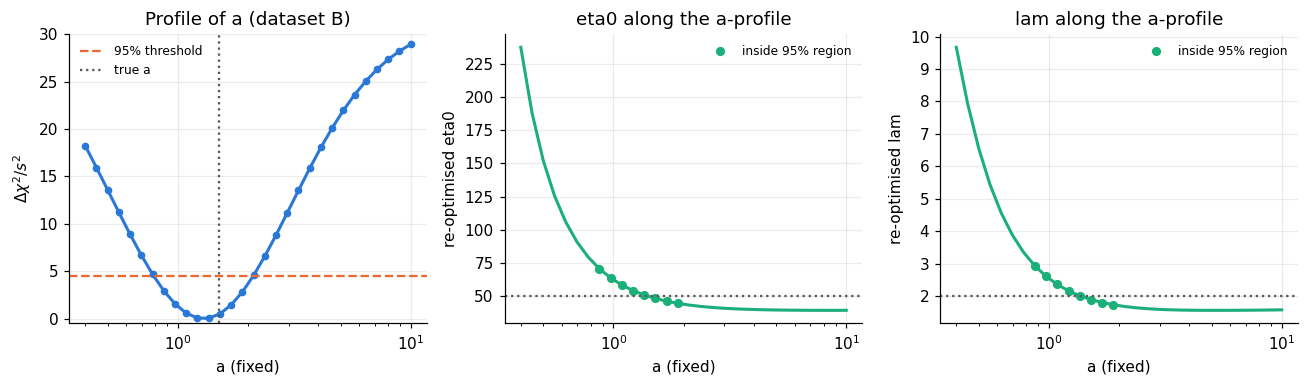

In [27]:
gB = cy_guess(gd_B, eta_B)
res_B4 = cy_model.fit(np.log(eta_B), cy_params(gB, fix=dict(eta_inf=0.0)), gd=gd_B)
ci_B4 = safe_conf_interval(res_B4)
summarize(res_B4, truth=CY_TRUE, ci=ci_B4)
print("\nCorrelation matrix:")
_ = correlation_matrix(res_B4)

a_grid = np.logspace(np.log10(0.4), np.log10(10), 30)
chi2_a, oth_a = profile(res_B4, "a", a_grid)
thr_a = profile_threshold(res_B4)
s2B = res_B4.chisqr / res_B4.nfree

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
axs[0].semilogx(a_grid, (chi2_a - res_B4.chisqr) / s2B, "o-", color=C_DATA, ms=4)
axs[0].axhline((thr_a - res_B4.chisqr) / s2B, color=C_FIT, ls="--", lw=1.5, label="95% threshold")
axs[0].axvline(CY_TRUE["a"], color=C_TRUE, ls=":", lw=1.5, label="true a")
axs[0].set(xlabel="a (fixed)", ylabel=r"$\Delta\chi^2/s^2$", title="Profile of a (dataset B)", ylim=(-0.5, 30)); axs[0].legend(fontsize=8)
for ax, k in zip(axs[1:], ["eta0", "lam"]):
    inside = chi2_a <= thr_a
    ax.semilogx(a_grid, oth_a[k], "-", color=C_ALT)
    ax.semilogx(a_grid[inside], oth_a[k][inside], "o", color=C_ALT, ms=5, label="inside 95% region")
    ax.axhline(CY_TRUE[k], color=C_TRUE, ls=":", lw=1.5)
    ax.set(xlabel="a (fixed)", ylabel=f"re-optimised {k}", title=f"{k} along the a-profile"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Inside the 95 % region, $a$ can roughly double, and $\eta_0$ and $\lambda$ move with it. The data constrain a *combination* of $(a, \eta_0, \lambda)$, not each one. A 2-D profile makes the shape visible. For each $(a, \eta_0)$ pair we re-optimise $\lambda$ and $n$; the contour is the joint 95 % confidence region (F-test with 2 fixed parameters).

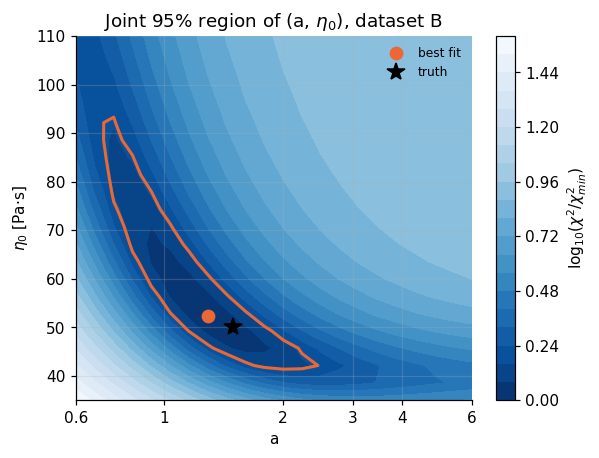

In [28]:
a_ax = np.logspace(np.log10(0.6), np.log10(6), 22)
e0_ax = np.linspace(35, 110, 22)
chi2_2d = np.full((e0_ax.size, a_ax.size), np.nan)
for i, e0 in enumerate(e0_ax):
    for j, aa in enumerate(a_ax):
        pp = res_B4.params.copy()
        pp["a"].set(value=aa, vary=False); pp["eta0"].set(value=e0, vary=False)
        chi2_2d[i, j] = cy_model.fit(np.log(eta_B), pp, gd=gd_B).chisqr

thr2 = profile_threshold(res_B4, nfix=2)
fig, ax = plt.subplots(figsize=(5.8, 4.3))
cs = ax.contourf(a_ax, e0_ax, np.log10(chi2_2d / res_B4.chisqr), levels=20, cmap="Blues_r")
ax.contour(a_ax, e0_ax, chi2_2d, levels=[thr2], colors=[C_FIT], linewidths=2)
ax.plot(res_B4.params["a"].value, res_B4.params["eta0"].value, "o", color=C_FIT, ms=8, label="best fit")
ax.plot(CY_TRUE["a"], CY_TRUE["eta0"], "*", color="k", ms=12, label="truth")
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 3, 4, 6]); ax.set_xticklabels(["0.6", "1", "2", "3", "4", "6"])
ax.minorticks_off(); ax.set(xlabel="a", ylabel=r"$\eta_0$ [Pa·s]", title=r"Joint 95% region of (a, $\eta_0$), dataset B")
plt.colorbar(cs, label=r"log$_{10}(\chi^2/\chi^2_{min})$"); ax.legend(fontsize=8, loc="upper right"); plt.show()

The orange contour is a long, curved "banana": small $a$ pairs with large $\eta_0$. A banana-shaped region is exactly where the symmetric stderr interval ($\hat p \pm t\cdot$SE, an ellipse) misrepresents the uncertainty. Always look at profiles when correlations exceed ~0.9.

### 2.7 Remedy: staged fitting (fix → fit → release → check)

This is the procedure you've probably been doing by instinct. Here it is made systematic:

1. **Fix $a=2$ (Carreau) and $\eta_\infty = 0$.** Fit $\eta_0, \lambda, n$. This 3-parameter problem is well posed and converges from almost any start.
2. **Release $a$**, starting from the step-1 values. The optimizer now starts at the bottom of the valley, so it doesn't get lost.
3. **Check:** did $\chi^2$ drop significantly (F-test, AIC)? Is the profile CI of $a$ two-sided and reasonably narrow? If yes, keep $a$ free. If not, report the fit **with $a$ fixed, and say so**. Note that a non-significant F-test does *not* mean $a=2$ is correct; it means the data can't tell.
4. Optionally repeat for $\eta_\infty$ (usually it fails the check; see §2.4).

In [29]:
def staged_cy_fit(gd, eta, a_fixed=2.0, verbose=True):
    y = np.log(eta)
    g = cy_guess(gd, eta)
    s1 = cy_model.fit(y, cy_params(g, fix=dict(a=a_fixed, eta_inf=0.0)), gd=gd)        # step 1
    p2 = s1.params.copy(); p2["a"].set(vary=True)                                      # step 2
    s2 = cy_model.fit(y, p2, gd=gd)
    F = (s1.chisqr - s2.chisqr) / (s2.chisqr / s2.nfree)
    pF = stats.f.sf(F, 1, s2.nfree)
    if verbose:
        print(f"step 1 (a={a_fixed} fixed): chi2={s1.chisqr:.5f}  AIC={s1.aic:.2f}")
        print(f"step 2 (a free)     : chi2={s2.chisqr:.5f}  AIC={s2.aic:.2f}   F-test p={pF:.3g}")
    return s1, s2

s1_B, s2_B = staged_cy_fit(gd_B, eta_B)
print("\n--- Step 1: a fixed at 2 ---")
summarize(s1_B, truth=CY_TRUE, ci=safe_conf_interval(s1_B))
print("\n--- Step 2: a released ---")
summarize(s2_B, truth=CY_TRUE, ci=safe_conf_interval(s2_B))

step 1 (a=2.0 fixed): chi2=0.02785  AIC=-117.98
step 2 (a free)     : chi2=0.02239  AIC=-120.13   F-test p=0.0751

--- Step 1: a fixed at 2 ---
   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
    eta0      43.99      1.833     4.2%   [40.11, 47.88]           [40.36, 48.57]                 50
 eta_inf          0        n/a      n/a   (fixed)                  (fixed)                      0.01
     lam      1.702     0.1511     8.9%   [1.381, 2.022]           [1.412, 2.1]                    2
       a          2        n/a      n/a   (fixed)                  (fixed)                       1.5
       n     0.3561   0.005482     1.5%   [0.3445, 0.3678]         [0.3441, 0.3679]             0.35

N = 19, free params = 3, chi-square = 0.02785, reduced chi-square = 0.00174 (residual s.d. = 0.0417)

--- Step 2: a released ---
   param       best

**Read these two tables carefully. They make the most important point in the notebook.**

* In step 1 the CIs for $\eta_0$ and $\lambda$ look *tight*, but they are **conditional on $a = 2$ being correct**. Since the true $a$ is 1.5, the step-1 interval for $\eta_0$ may not even contain the true value. Fixing a parameter doesn't remove its uncertainty; it hides it.
* In step 2 the intervals are wider, and honest. Freeing $a$ starting from the step-1 solution converges to the global minimum reliably, unlike the random starts in §2.6.1.

So when you fix a parameter you have two legitimate ways to report:

1. **State the assumption:** "$\eta_0 = 46 \pm 2$ Pa·s *for the Carreau model ($a=2$, $\eta_\infty = 0$)*".
2. **Propagate it:** repeat the fit with the fixed value varied over its plausible range (e.g. $a \in [1, 3]$) and report the spread, or use the $a$-profile above, which does exactly that.

#### Visual comparison

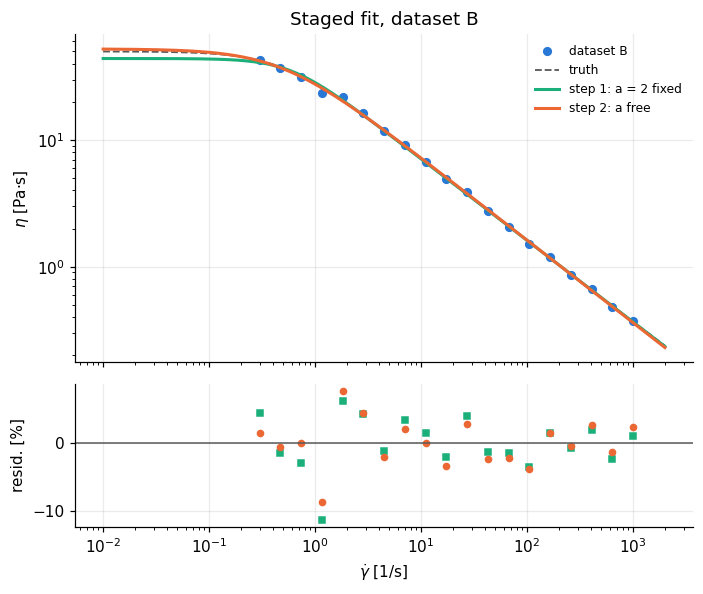

In [30]:
gfB = np.logspace(-2, 3.3, 300)
fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
ax.loglog(gd_B, eta_B, "o", color=C_DATA, ms=5, label="dataset B")
ax.loglog(gfB, cy(gfB, **CY_TRUE), "--", color=C_TRUE, lw=1.2, label="truth")
ax.loglog(gfB, np.exp(s1_B.eval(gd=gfB)), color=C_ALT, label="step 1: a = 2 fixed")
ax.loglog(gfB, np.exp(s2_B.eval(gd=gfB)), color=C_FIT, label="step 2: a free")
ax.set(ylabel=r"$\eta$ [Pa·s]", title="Staged fit, dataset B"); ax.legend(fontsize=8)
axr.semilogx(gd_B, 100 * s1_B.residual, "s", color=C_ALT, ms=4)
axr.semilogx(gd_B, 100 * s2_B.residual, "o", color=C_FIT, ms=4)
axr.axhline(0, color=C_TRUE, lw=1); axr.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel="resid. [%]")
plt.tight_layout(); plt.show()

The two curves are nearly indistinguishable *inside* the data range and differ mainly in the extrapolated plateau below 0.3 s⁻¹. **When a parameter is mostly "about" a region you didn't measure, no fitting trick will recover it.**

### 2.8 How much data does $a$ (and $\eta_0$) need?

$a$ controls the *curvature* of the transition around $\lambda\dot\gamma \approx 1$. To measure it you need the plateau on one side and the power-law on the other, with enough points in between. Two experiments (staged fits with $\eta_\infty=0$, 20 replicates each):

1. vary the lowest shear rate, i.e. how much plateau is captured ($\lambda\dot\gamma_\min$);
2. vary the point density (points per decade) over a fixed range.

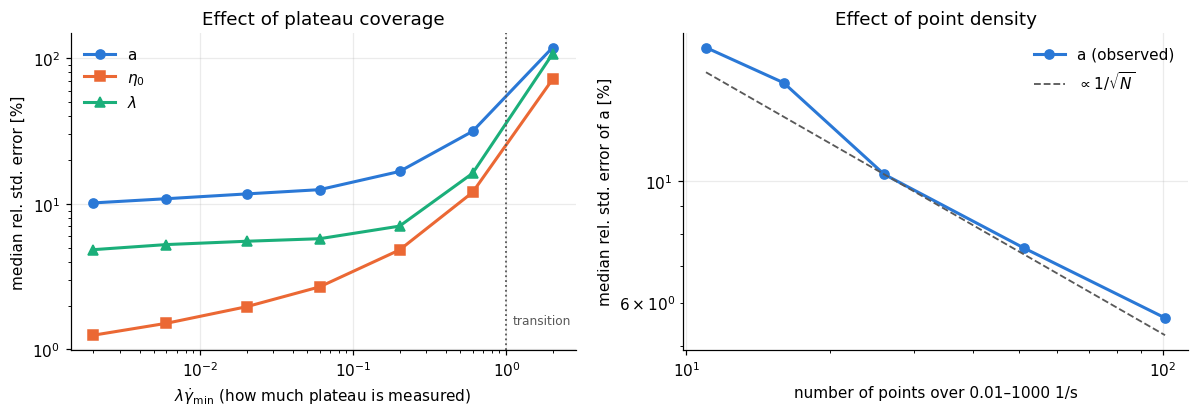

lam*gd_min =  0.002:  rel.SE(a) =  10.1%   rel.SE(eta0) =   1.3%
lam*gd_min =  0.006:  rel.SE(a) =  10.8%   rel.SE(eta0) =   1.5%
lam*gd_min =   0.02:  rel.SE(a) =  11.7%   rel.SE(eta0) =   2.0%
lam*gd_min =   0.06:  rel.SE(a) =  12.5%   rel.SE(eta0) =   2.7%
lam*gd_min =    0.2:  rel.SE(a) =  16.7%   rel.SE(eta0) =   4.8%
lam*gd_min =    0.6:  rel.SE(a) =  31.5%   rel.SE(eta0) =  12.0%
lam*gd_min =      2:  rel.SE(a) = 118.7%   rel.SE(eta0) =  71.8%


In [31]:
rng_a = np.random.default_rng(8)
n_rep = 20

def med_rel_se(results, k):
    v = [r.params[k].stderr / r.params[k].value if r.params[k].stderr is not None else np.inf for r in results]
    return np.median(v)

# 1) plateau coverage
gmins = np.array([1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0])
cov_a, cov_e0, cov_l = [], [], []
for gmin in gmins:
    rs = [staged_cy_fit(*make_cy_data(gmin, 1000, rng=rng_a), verbose=False)[1] for _ in range(n_rep)]
    cov_a.append(med_rel_se(rs, "a")); cov_e0.append(med_rel_se(rs, "eta0")); cov_l.append(med_rel_se(rs, "lam"))

# 2) point density over 0.01-1000
ppds = np.array([2, 3, 5, 10, 20])
den_a = []
for ppd in ppds:
    rs = [staged_cy_fit(*make_cy_data(0.01, 1000, pts_per_decade=ppd, rng=rng_a), verbose=False)[1] for _ in range(n_rep)]
    den_a.append(med_rel_se(rs, "a"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9))
x = CY_TRUE["lam"] * gmins
for vals, k, c, m in [(cov_a, "a", C_DATA, "o"), (cov_e0, r"$\eta_0$", C_FIT, "s"), (cov_l, r"$\lambda$", C_ALT, "^")]:
    ax1.loglog(x, 100 * np.array(vals), marker=m, color=c, label=k)
ax1.axvline(1, color=C_TRUE, ls=":", lw=1.2); ax1.text(1.1, ax1.get_ylim()[0] * 1.5, "transition", color=C_TRUE, fontsize=8)
ax1.set(xlabel=r"$\lambda\dot\gamma_\min$ (how much plateau is measured)", ylabel="median rel. std. error [%]",
        title="Effect of plateau coverage"); ax1.legend()

npts = np.round(5 * ppds + 1)
ax2.loglog(npts, 100 * np.array(den_a), "o-", color=C_DATA, label="a (observed)")
ax2.loglog(npts, 100 * den_a[2] * np.sqrt(npts[2] / npts), "--", color=C_TRUE, lw=1.2, label=r"$\propto 1/\sqrt{N}$")
ax2.set(xlabel="number of points over 0.01–1000 1/s", ylabel="median rel. std. error of a [%]",
        title="Effect of point density"); ax2.legend()
plt.tight_layout(); plt.show()

for gm, ea, ee in zip(gmins, cov_a, cov_e0):
    print(f"lam*gd_min = {CY_TRUE['lam']*gm:6.3g}:  rel.SE(a) = {100*ea:5.1f}%   rel.SE(eta0) = {100*ee:5.1f}%")

**Take-aways.**

* **Range beats density.** Measuring the plateau down to $\lambda\dot\gamma_\min \approx 0.01$–$0.1$ shrinks the uncertainty in $a$ and $\eta_0$ dramatically. Adding more points within the same range helps only as $1/\sqrt{N}$: four times the points for half the error.
* Once $\lambda\dot\gamma_\min \gtrsim 1$, $a$ and $\eta_0$ become essentially unidentifiable, and fixing $a$ (with an honest caveat) is the only sensible option.
* A rule of thumb for the full CY model: **≥ 1 decade of clear zero-shear plateau, ≥ 1.5–2 decades of power-law, and ≥ 5 points per decade through the transition.** $\eta_\infty$ additionally needs data out near $\dot\gamma^*$ (§2.5).
* If low-rate steady shear is out of reach, small-amplitude oscillatory data plus the Cox–Merz rule ($\eta(\dot\gamma) \approx |\eta^*(\omega)|$) can often extend the plateau. Check that Cox–Merz holds for your material.

### 2.9 Shear-rate windows for Carreau–Yasuda

The same window analysis as §1.8, now for the five CY parameters. Each one dominates a different part of the curve:

| window | shear rates (here) | $\lambda\dot\gamma$ | what the curve looks like | should determine |
|---|---|---|---|---|
| **zero-shear plateau** | 0.001–0.05 s⁻¹ | 0.002–0.1 | flat | $\eta_0$ |
| **transition** | 0.05–5 s⁻¹ | 0.1–10 | bending over | $\eta_0, \lambda, a$ (and a little of $n$) |
| **power-law** | 10–3000 s⁻¹ | 20–6000 | straight line on log–log | $n$ and *one combination* of $\eta_0$ and $\lambda$ |
| **approach to $\eta_\infty$** | 10⁴–10⁶ s⁻¹ | — | power law flattening out | $\eta_\infty$, $n$, and the same combination |
| full | 0.001–10⁶ s⁻¹ | | everything | all five |

The last window is beyond a rotational rheometer (it would need capillary or slit rheometry), but it's the only place $\eta_\infty$ can be seen.

#### 2.9.1 Sensitivity curves

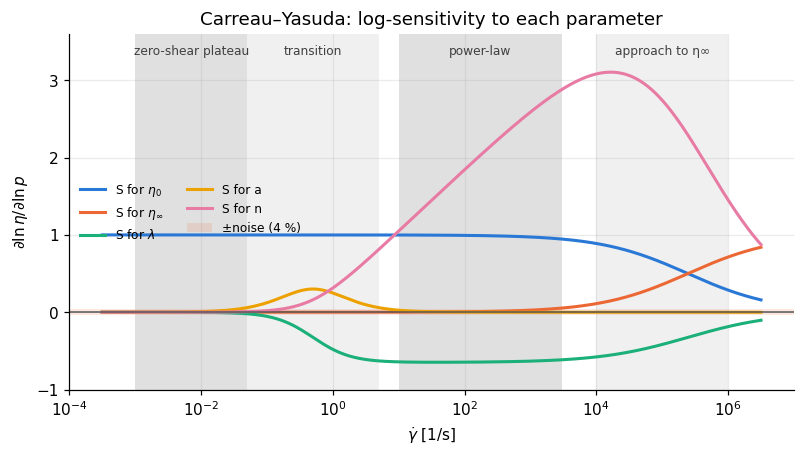

In [32]:
CY_WINDOWS = [("zero-shear plateau", 1e-3, 0.05), ("transition", 0.05, 5.0), ("power-law", 10.0, 3000.0),
              ("approach to η∞", 1e4, 1e6), ("full", 1e-3, 1e6)]
CY_LABELS = [r"$\eta_0$", r"$\eta_\infty$", r"$\lambda$", "a", "n"]

g_s = np.logspace(-3.5, 6.5, 500)
S_cy = log_sensitivity(cy, g_s, CY_TRUE)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
shade_windows(ax, CY_WINDOWS)
for (k, s), c, lab in zip(S_cy.items(), SERIES_COLORS, CY_LABELS):
    ax.semilogx(g_s, s, color=c, label=f"S for {lab}")
ax.axhline(0, color=C_TRUE, lw=1)
ax.axhspan(-NOISE, NOISE, color=C_FIT, alpha=0.15, lw=0, label="±noise (4 %)")
ax.set(xlabel=r"$\dot\gamma$ [1/s]", ylabel=r"$\partial\ln\eta/\partial\ln p$",
       title="Carreau–Yasuda: log-sensitivity to each parameter", ylim=(-1.0, 3.6))
ax.legend(loc="center left", fontsize=8, ncol=2); plt.show()

What the curves say:

* $S_{\eta_0}$ is 1 on the plateau and **stays at 1 all the way through the power-law region**. In the power law, $\eta \approx \eta_0\lambda^{n-1}\dot\gamma^{\,n-1}$, so raising $\eta_0$ by 10 % has the same effect as a matching change in $\lambda$. There, $S_\lambda = n-1$ is *also constant*. Two constant sensitivities over a window are proportional, so **the power-law region can only determine the combination $K = \eta_0\lambda^{\,n-1}$** (the power-law consistency), never $\eta_0$ and $\lambda$ separately.
* $S_a$ is a bump confined to the transition: it is zero on the plateau and decays in the power-law region. **$a$ can only be measured from data in the transition.**
* $S_n$ grows like $\ln(\lambda\dot\gamma)$ beyond the transition, so the power-law window measures $n$ well.
* $S_{\eta_\infty}$ stays below the noise line until $\sim10^4$ s⁻¹. That is §2.5's conclusion in one picture.

#### 2.9.2 Expected uncertainty in each window

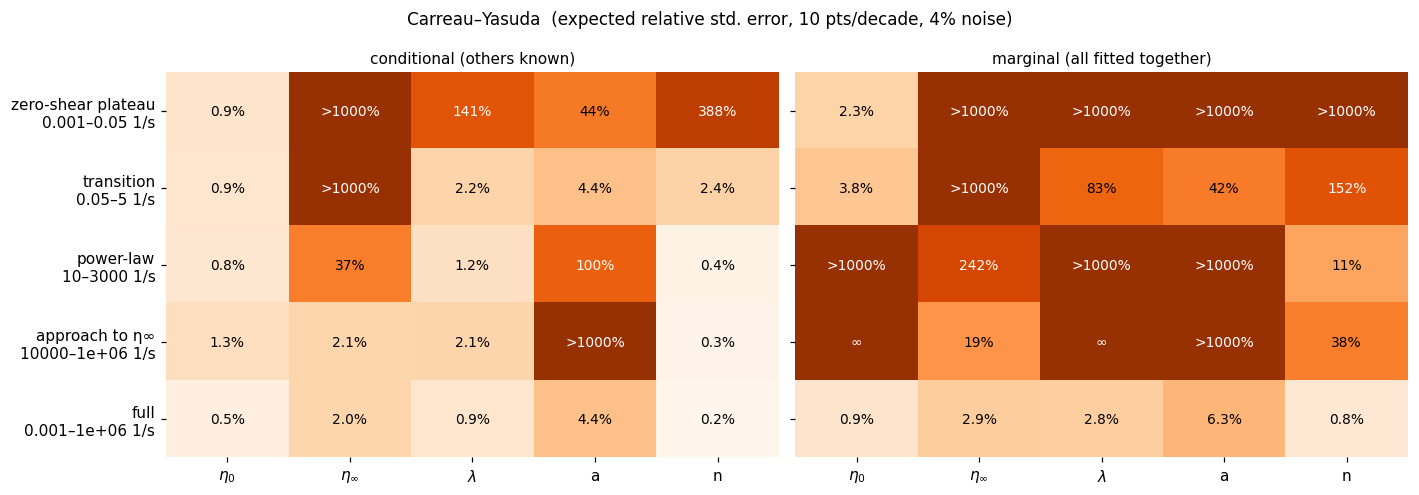

In [33]:
cond_cy, marg_cy = se_heatmaps(cy, CY_TRUE, CY_WINDOWS, "Carreau–Yasuda", labels=CY_LABELS)

The **conditional** map shows which parameters a window can see at all; the **marginal** map shows what a 5-parameter fit can actually deliver:

* **Plateau:** only $\eta_0$. Every other parameter's expected error is enormous, even conditionally.
* **Transition:** $\eta_0$, $\lambda$ and $a$ are all visible, but the marginal errors in $\lambda$, $a$ and especially $n$ are inflated by correlation. This is the §2.6 problem again: across one or two decades the sensitivities of $\eta_0$, $\lambda$, $a$, $n$ overlap. $\eta_\infty$ is invisible.
* **Power-law:** $n$ comes out well. $\eta_0$ and $\lambda$ each look fine *conditionally* but are hopeless *marginally*. The huge gap between the two maps is the signature of the $\eta_0$–$\lambda$ combination problem. $a$ is invisible.
* **Approach to $\eta_\infty$:** $\eta_\infty$ and $n$ are measurable; $\eta_0$, $\lambda$, $a$ are not.
* **Full range:** conditional ≈ marginal for every parameter. Each one has a region of its own.

#### 2.9.3 Real fits in each window
As in §1.8.3: one dataset per window, all five parameters free, **started at the true values** so that any failure is due to the data. Panels without a band are fits where `lmfit` could not estimate uncertainties at all (singular covariance matrix), which is itself the diagnosis.

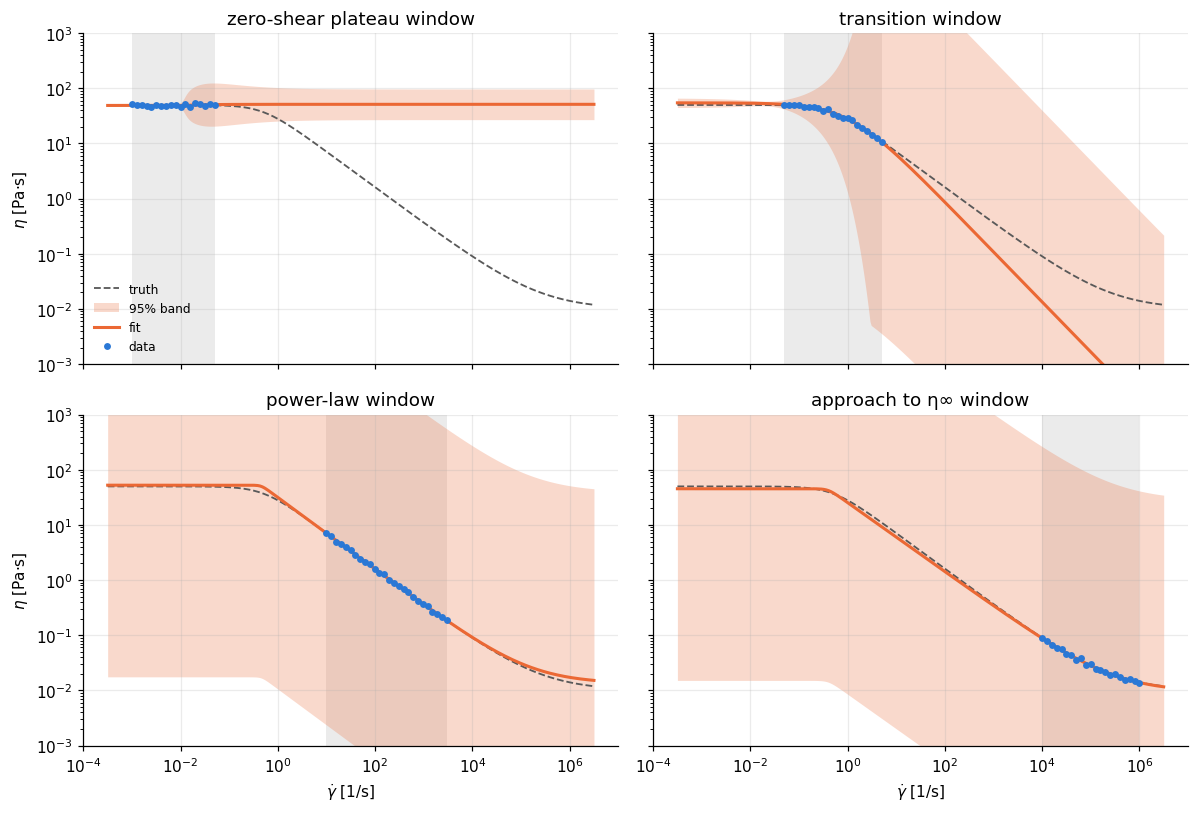


===== zero-shear plateau window (0.001–0.05 1/s, 18 points) =====
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
    eta0      48.94     0.7945     1.6%   [47.22, 50.65]                 50
 eta_inf      51.28      15.19    29.6%   [18.47, 84.1]                0.01
     lam       90.3      335.3   371.3%   [-634.1, 814.7]                 2
       a         10      252.8  2527.8%   [-536.1, 556.1]               1.5
       n  4.339e-09       17.2    >1e4%   [-37.15, 37.15]              0.35

N = 18, free params = 5, chi-square = 0.03244, reduced chi-square = 0.0025 (residual s.d. = 0.05)

===== transition window (0.05–5 1/s, 21 points) =====
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
    eta0      54.58      5.206     9.5%   [43.55, 65.62]                 50
 eta_inf  1.292e-06

In [34]:
rng_cw = np.random.default_rng(17)
win_fits_cy = {}
g_plot = np.logspace(-3.5, 6.5, 400)
fig, axs = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, (label, lo, hi) in zip(axs.ravel(), CY_WINDOWS[:4]):
    gd_w, eta_w = make_cy_data(lo, hi, pts_per_decade=10, rng=rng_cw)
    r = cy_model.fit(np.log(eta_w), cy_params(CY_TRUE), gd=gd_w)
    win_fits_cy[label] = (gd_w, eta_w, r)
    ax.axvspan(lo, hi, color="0.92", zorder=0, lw=0)
    ax.loglog(g_plot, cy(g_plot, **CY_TRUE), "--", color=C_TRUE, lw=1.2, label="truth")
    ln_fit = r.eval(gd=g_plot)
    if r.errorbars:
        band = np.clip(r.eval_uncertainty(gd=g_plot, sigma=0.95), 0, 8)
        ax.fill_between(g_plot, np.exp(ln_fit - band), np.exp(ln_fit + band), color=C_FIT, alpha=0.25, lw=0, label="95% band")
    ax.loglog(g_plot, np.exp(ln_fit), color=C_FIT, label="fit")
    ax.loglog(gd_w, eta_w, "o", color=C_DATA, ms=3.5, label="data")
    ax.set(title=f"{label} window" + ("" if r.errorbars else "  (no error bars)"), ylim=(1e-3, 1e3))
for ax in axs[1]: ax.set_xlabel(r"$\dot\gamma$ [1/s]")
for ax in axs[:, 0]: ax.set_ylabel(r"$\eta$ [Pa·s]")
axs[0, 0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

for label, (gd_w, eta_w, r) in win_fits_cy.items():
    print(f"\n===== {label} window ({gd_w.min():g}–{gd_w.max():g} 1/s, {gd_w.size} points) =====")
    summarize(r, truth=CY_TRUE)

Again, every fit is excellent *inside its window*, and the parameter values outside the window's reach are arbitrary, sometimes wildly so, even though we started at the truth. When uncertainties *are* reported for an invisible parameter they are enormous, or (worse) deceptively finite because the optimizer stopped at a bound. Always compare against the sensitivity picture.

#### 2.9.4 Fit the model the window can actually see

The constructive move is to fit a **reduced model** containing only the parameters the window can determine. Each reduction of CY is a classical model:

| window | reduced model | parameters | relation to CY |
|---|---|---|---|
| plateau | Newtonian: $\eta=\eta_0$ | $\eta_0$ | same $\eta_0$ |
| power-law | power law: $\eta = K\dot\gamma^{\,n-1}$ | $K, n$ | $K = \eta_0\lambda^{\,n-1}$ |
| approach to $\eta_\infty$ | Sisko: $\eta=\eta_\infty + K\dot\gamma^{\,n-1}$ | $\eta_\infty, K, n$ | same $\eta_\infty$, $n$; $K=\eta_0\lambda^{\,n-1}$ |

These reduced fits are well conditioned, and their parameters can be compared with the CY truth.

In [35]:
def log_newtonian(gd, eta0):
    return np.log(eta0) * np.ones_like(gd)

def log_powerlaw(gd, K, n):
    return np.log(K) + (n - 1.0) * np.log(gd)

def log_sisko(gd, eta_inf, K, n):
    return np.log(eta_inf + K * gd ** (n - 1.0))

K_true = CY_TRUE["eta0"] * CY_TRUE["lam"] ** (CY_TRUE["n"] - 1)
REDUCED_TRUTH = dict(eta0=CY_TRUE["eta0"], K=K_true, n=CY_TRUE["n"], eta_inf=CY_TRUE["eta_inf"])
print(f"power-law consistency implied by the CY truth: K = eta0 * lam^(n-1) = {K_true:.4g} Pa·s^n\n")

reduced = {
    "zero-shear plateau": (Model(log_newtonian), dict(eta0=10.0), {}),
    "power-law":          (Model(log_powerlaw), dict(K=10.0, n=0.5), dict(K=(1e-8, None), n=(0.0, 1.0))),
    "approach to η∞":     (Model(log_sisko), dict(eta_inf=0.005, K=10.0, n=0.5),
                           dict(eta_inf=(0.0, None), K=(1e-8, None), n=(0.0, 1.0))),
}
red_fits = {}
for label, (m, start, bounds) in reduced.items():
    gd_w, eta_w, _ = win_fits_cy[label]
    p = m.make_params(**start)
    for k, (lo, hi) in bounds.items():
        if lo is not None: p[k].set(min=lo)
        if hi is not None: p[k].set(max=hi)
    red_fits[label] = r = m.fit(np.log(eta_w), p, gd=gd_w)
    print(f"===== {label} window -> {m.func.__name__.replace('log_', '')} model =====")
    summarize(r, truth=REDUCED_TRUTH, ci=safe_conf_interval(r))
    print()

power-law consistency implied by the CY truth: K = eta0 * lam^(n-1) = 31.86 Pa·s^n

===== zero-shear plateau window -> newtonian model =====
conf_interval() failed: MinimizerException: Cannot determine Confidence Intervals with < 2 variables
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
    eta0       49.4     0.5331     1.1%   [48.28, 50.53]                 50

N = 18, free params = 1, chi-square = 0.03563, reduced chi-square = 0.0021 (residual s.d. = 0.0458)

===== power-law window -> powerlaw model =====
   param       best     stderr  rel.err   95% CI (stderr*t)        95% CI (profile)             true
----------------------------------------------------------------------------------------------------
       K      30.39      0.695     2.3%   [28.95, 31.82]           [28.99, 31.86]              31.86
       n     0.3597   0.004211     1.2%   [0.351, 0.3684]          [0.351, 0.3

The reduced models give tight, honest intervals, and they contain the truth (up to a small bias where a neglected parameter isn't quite zero; e.g. $\eta_\infty$ slightly steepens the apparent power law near 3000 s⁻¹).

#### 2.9.5 Combining windows: borrow a parameter from another measurement

The transition window sees $\eta_0$, $\lambda$ and $a$, but the fit is dragged down by its weak grip on $n$. The power-law window, by contrast, measures $n$ well. This is the legitimate version of "fix a parameter to get the others": **fix $n$ at the value measured in another window**, and propagate that value's uncertainty by refitting at $n \pm 2$ SE.

In [36]:
gd_t, eta_t, r_t5 = win_fits_cy["transition"]
r_pl = red_fits["power-law"]
n_hat, n_se = r_pl.params["n"].value, r_pl.params["n"].stderr
print(f"n from the power-law window: {n_hat:.4f} ± {n_se:.4f}\n")

# eta_inf is invisible in the transition window: fix it at 0 throughout
p = cy_params(CY_TRUE, fix=dict(eta_inf=0.0))
r_t4 = cy_model.fit(np.log(eta_t), p, gd=gd_t)
print("Transition window, eta_inf = 0, n free:")
summarize(r_t4, truth=CY_TRUE)

rows = []
for n_fix in [n_hat - 2 * n_se, n_hat, n_hat + 2 * n_se]:
    p = cy_params(CY_TRUE, fix=dict(eta_inf=0.0, n=n_fix))
    r = cy_model.fit(np.log(eta_t), p, gd=gd_t)
    rows.append((n_fix, r))
print("\nTransition window, n fixed from the power-law window:")
summarize(rows[1][1], truth=CY_TRUE)

print("\nSensitivity to the borrowed n (refit at n_hat ± 2 SE):")
print(f"{'n fixed':>8}" + "".join(f"{k:>16}" for k in ["eta0", "lam", "a"]))
for n_fix, r in rows:
    print(f"{n_fix:8.4f}" + "".join(f"{r.params[k].value:9.4g} ± {fmt(r.params[k].stderr, 2):<5}" for k in ["eta0", "lam", "a"]))

n from the power-law window: 0.3597 ± 0.0042

Transition window, eta_inf = 0, n free:
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
    eta0      54.59      3.713     6.8%   [46.76, 62.42]                 50
 eta_inf          0        n/a      n/a   (fixed)                      0.01
     lam     0.9385     0.8546    91.1%   [-0.8647, 2.742]                2
       a     0.8934     0.2726    30.5%   [0.3182, 1.469]               1.5
       n    0.09053      0.329   363.4%   [-0.6036, 0.7847]            0.35

N = 21, free params = 4, chi-square = 0.03714, reduced chi-square = 0.00218 (residual s.d. = 0.0467)

Transition window, n fixed from the power-law window:
   param       best     stderr  rel.err   95% CI (stderr*t)            true
---------------------------------------------------------------------------
    eta0       51.6       1.79     3.5%   [47.84, 55.36]                 

Borrowing $n$ shrinks the uncertainty in $\lambda$ and $a$ substantially, and the ±2 SE refits show how much of the borrowed value's own uncertainty carries through. Report the total: the statistical error from the fit *plus* the spread from the borrowed parameter.

In practice the simplest way to combine windows is to **fit all the data together**: put several datasets (rotational, oscillatory with Cox–Merz, capillary) in one array and fit once. The joint fit "borrows" automatically and gets the correlations right. The window analysis tells you *which* instruments and ranges you need in that combined dataset.

**CY window take-aways**
* Each CY parameter has a home region: $\eta_0$ on the plateau, $a$ only in the transition, $n$ in the power law, $\eta_\infty$ near $\dot\gamma^*$. $\lambda$ is located by where the plateau ends, so it needs the plateau *and* the bend.
* The power-law region alone determines only $n$ and $K=\eta_0\lambda^{n-1}$. If that's all you have, fit a power law and report $K$, not $\eta_0$ and $\lambda$.
* A fit that looks perfect inside the window can have arbitrary values for parameters that live outside it. Check the sensitivity curves, and fit the reduced model the window supports.

### 2.10 (Optional) Bayesian check with MCMC via `lmfit` + `emcee`

For banana-shaped problems a posterior sample shows the full shape of the uncertainty with no quadratic approximation. `lmfit` runs `emcee` through the same `Model.fit` interface. With `is_weighted=False`, `emcee` also samples the noise level (as `__lnsigma`). The flat priors are the parameter bounds. This cell is skipped if `emcee` is not installed (`pip install emcee`). It uses `lmfit.minimize` with an explicit residual function rather than `Model.fit(method='emcee')`, because the latter needs pandas to build the flattened chain.

In [37]:
try:
    import emcee  # noqa: F401
    HAVE_EMCEE = True
except ImportError:
    HAVE_EMCEE = False
    print("emcee not installed - skipping the MCMC cell (pip install emcee to run it).")

if HAVE_EMCEE:
    # We call lmfit.minimize() rather than Model.fit(method="emcee"): Model.fit copies every
    # attribute of the result, including `flatchain`, which requires pandas. minimize() avoids
    # that, and we read the plain NumPy array `mc.chain` instead.
    def resid_B(pars):
        v = pars.valuesdict()
        return log_cy(gd_B, v["eta0"], v["eta_inf"], v["lam"], v["a"], v["n"]) - np.log(eta_B)

    p_mc = s2_B.params.copy()
    p_mc.add("__lnsigma", value=np.log(np.sqrt(s2_B.redchi)), min=np.log(1e-3), max=np.log(1.0))
    mc = lmfit.minimize(resid_B, p_mc, method="emcee", nan_policy="omit",
                        steps=4000, burn=1000, thin=10, nwalkers=40, is_weighted=False, progress=False)
    names = list(mc.var_names)
    chain = mc.chain.reshape(-1, mc.chain.shape[-1])      # (samples, parameters), burn-in/thinning already applied
    col = lambda k: chain[:, names.index(k)]
    print("Posterior medians and 95% credible intervals:")
    for k in ["eta0", "lam", "a", "n"]:
        lo, med, hi = np.percentile(col(k), [2.5, 50, 97.5])
        print(f"  {k:>5}: {med:8.4g}   [{lo:.4g}, {hi:.4g}]   (true {CY_TRUE[k]})")
    print(f"  noise s.d. (exp __lnsigma): {np.exp(np.median(col('__lnsigma'))):.3f}  (true {NOISE})")
    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.plot(col("a"), col("eta0"), ".", color=C_DATA, ms=2, alpha=0.3)
    ax.plot(CY_TRUE["a"], CY_TRUE["eta0"], "*", color="k", ms=12, label="truth")
    ax.set(xscale="log", xlabel="a", ylabel=r"$\eta_0$ [Pa·s]", title="MCMC posterior sample, dataset B"); ax.legend()
    plt.show()

emcee not installed - skipping the MCMC cell (pip install emcee to run it).


---
## 3. Checklist and notes on tools

### A fitting checklist for GNF models
1. **Plot the data on log–log axes first.** Which regions (plateaus, power-law, yield) are actually present? Parameters tied to regions you didn't measure can't be estimated.
2. **Fit in log space** (or weight by $1/y$, or by $1/\sigma_i$ if you have measurement uncertainties).
3. **Build initial guesses from the data** (plateau value, slope, half-drop rate). Never start a bounded parameter exactly on its bound.
4. **For CY, fit in stages:** fix $a=2$ and $\eta_\infty=0$, then release $a$, then (rarely) $\eta_\infty$. Use multistart when in doubt.
5. **Look at residuals.** Systematic patterns mean model error; then the CIs are meaningless.
6. **Report CIs, preferably profile-based** (`result.conf_interval()`). Look at the correlation matrix; if $|\rho| > 0.9$, plot profiles or 2-D regions.
7. **Decide whether each parameter earns its keep:** a CI that includes 0 or is one-sided, an F-test, AIC/BIC.
8. **When you fix a parameter, say so,** and remember the remaining CIs are conditional on it. Where it matters, propagate the effect by refitting over a plausible range of the fixed value.
9. **Check which parameters your shear-rate range can see.** Plot the log-sensitivities $\partial\ln y/\partial\ln p$ and compute the expected errors (§1.8.2, §2.9.2). If the range only sees some parameters, fit the reduced model it supports (power law, Sisko, Newtonian) or borrow the missing parameters from another measurement.
10. **Use simulation to plan experiments.** The loops in §1.6, §2.5 and §2.8 answer "what shear-rate range and point density do I need?" *before* you spend rheometer time. Plug in your own expected parameters.

### Is `lmfit` the right tool?
For this job, **yes**. It is a good fit for routine GNF parameter estimation: named parameters, bounds, `vary=False` to fix, `expr=` for derived and constrained parameters with uncertainty propagation, built-in profile CIs (`conf_interval`, `conf_interval2d`), AIC/BIC, and an MCMC backend. A few suggestions on top of what you are probably already doing:

* **Try `method='least_squares'`** (SciPy's trust-region-reflective solver) for problems with parameters near bounds, such as $\eta_\infty$ near 0. `lmfit` then passes the bounds to the solver directly instead of using the sine/square-root transformation of the default `leastsq`, which can stall at a bound and distort standard errors there.
* **Use a global optimizer for multimodal fits:** `method='differential_evolution'` (needs finite bounds on all parameters) or `basinhopping`, then polish with a local `leastsq` fit and compute CIs from that.
* **For banana-shaped uncertainty, use MCMC** (`method='emcee'`, §2.10) or a full Bayesian tool such as PyMC. That also lets you put *informative priors* on parameters like $a$ (e.g. "$a$ is usually 0.5–3 for polymer melts"). A prior is the principled middle ground between "fixed" and "free".
* **Consider re-parameterizing** in terms of well-determined quantities: $K_\text{ref}$ at a mid-range shear rate instead of $K$ (§1.5), or $\log\lambda$ when $\lambda$ spans decades.
* Bare SciPy (`curve_fit`/`least_squares`) is fine for one-off fits, but it gives you only the covariance matrix. You would have to write the profile-likelihood machinery yourself, so `lmfit` is the better choice here.